# MCP Advanced Features

This notebook covers advanced server utilities (filters, completions, notifications), advanced client features (roots, elicitations, sampling), building custom MCP clients in Python, and constructing agentic workflows with Cloudflare Workers AI and Durable Objects.

## Table of Contents

- [Module 01: Advanced Server Features](#module-01-advanced-server-features)
- [Module 02: Advanced Client Features](#module-02-advanced-client-features)
- [Module 03: Custom MCP Clients](#module-03-custom-mcp-clients)
- [Module 04: Agentic Workflows with MCP](#module-04-agentic-workflows-with-mcp)

In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))

## Module 01: Advanced Server Features

This module covers three advanced server-side utilities: **filters** (middleware for modifying the request-response pipeline), **completions** (autocomplete suggestions for prompt and resource template arguments), and **change/progress notifications** (real-time updates sent from server to client).

### Filters

**Filters** are middleware that can modify the request-response pipeline in an MCP server. They are not part of the MCP specification itself — they are an SDK-level concept you implement.

Filters are well-suited for cross-cutting concerns:
- **Logging** — record requests and responses
- **Authentication** — verify caller identity
- **Authorization** — enforce access rules
- **Caching** — short-circuit repeated requests

When a `tools/list` request arrives, the normal flow is: receive request → find registered tools → return list. With a filter, a "Filter list" step is injected between finding tools and returning the list.


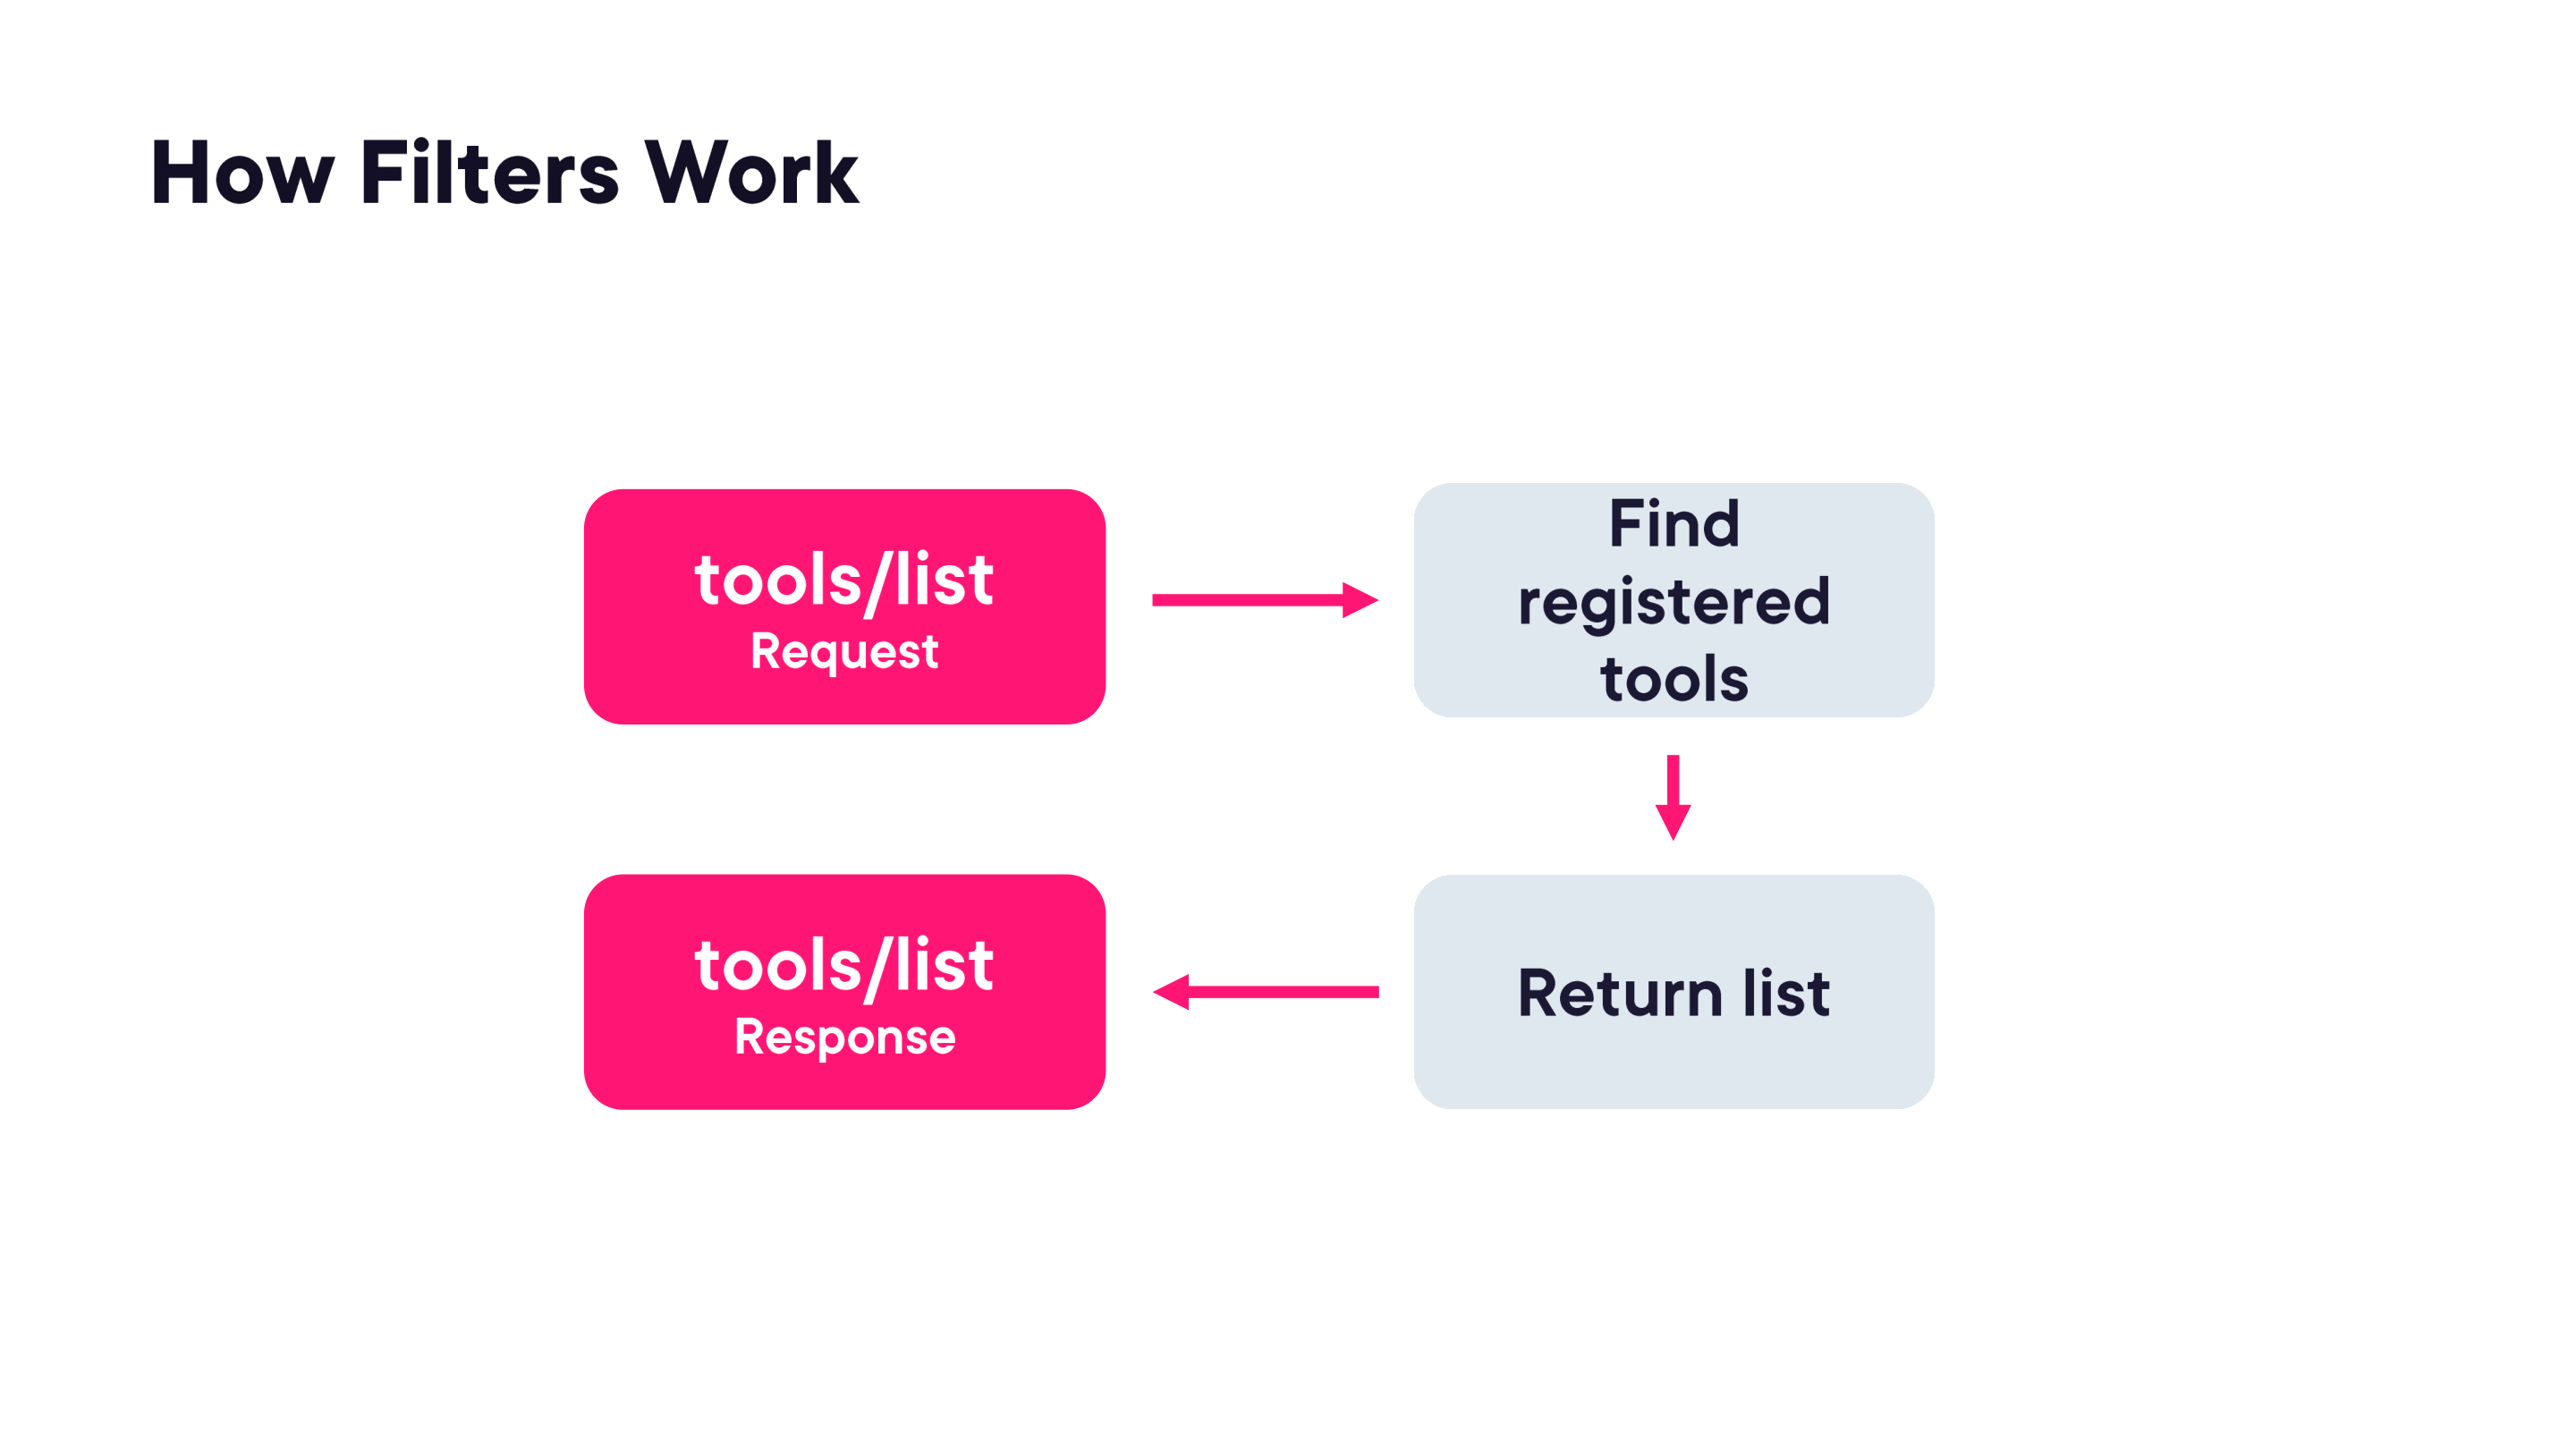

In [2]:
render_diagram(Path("assets/01-filter-request-pipeline.png"))


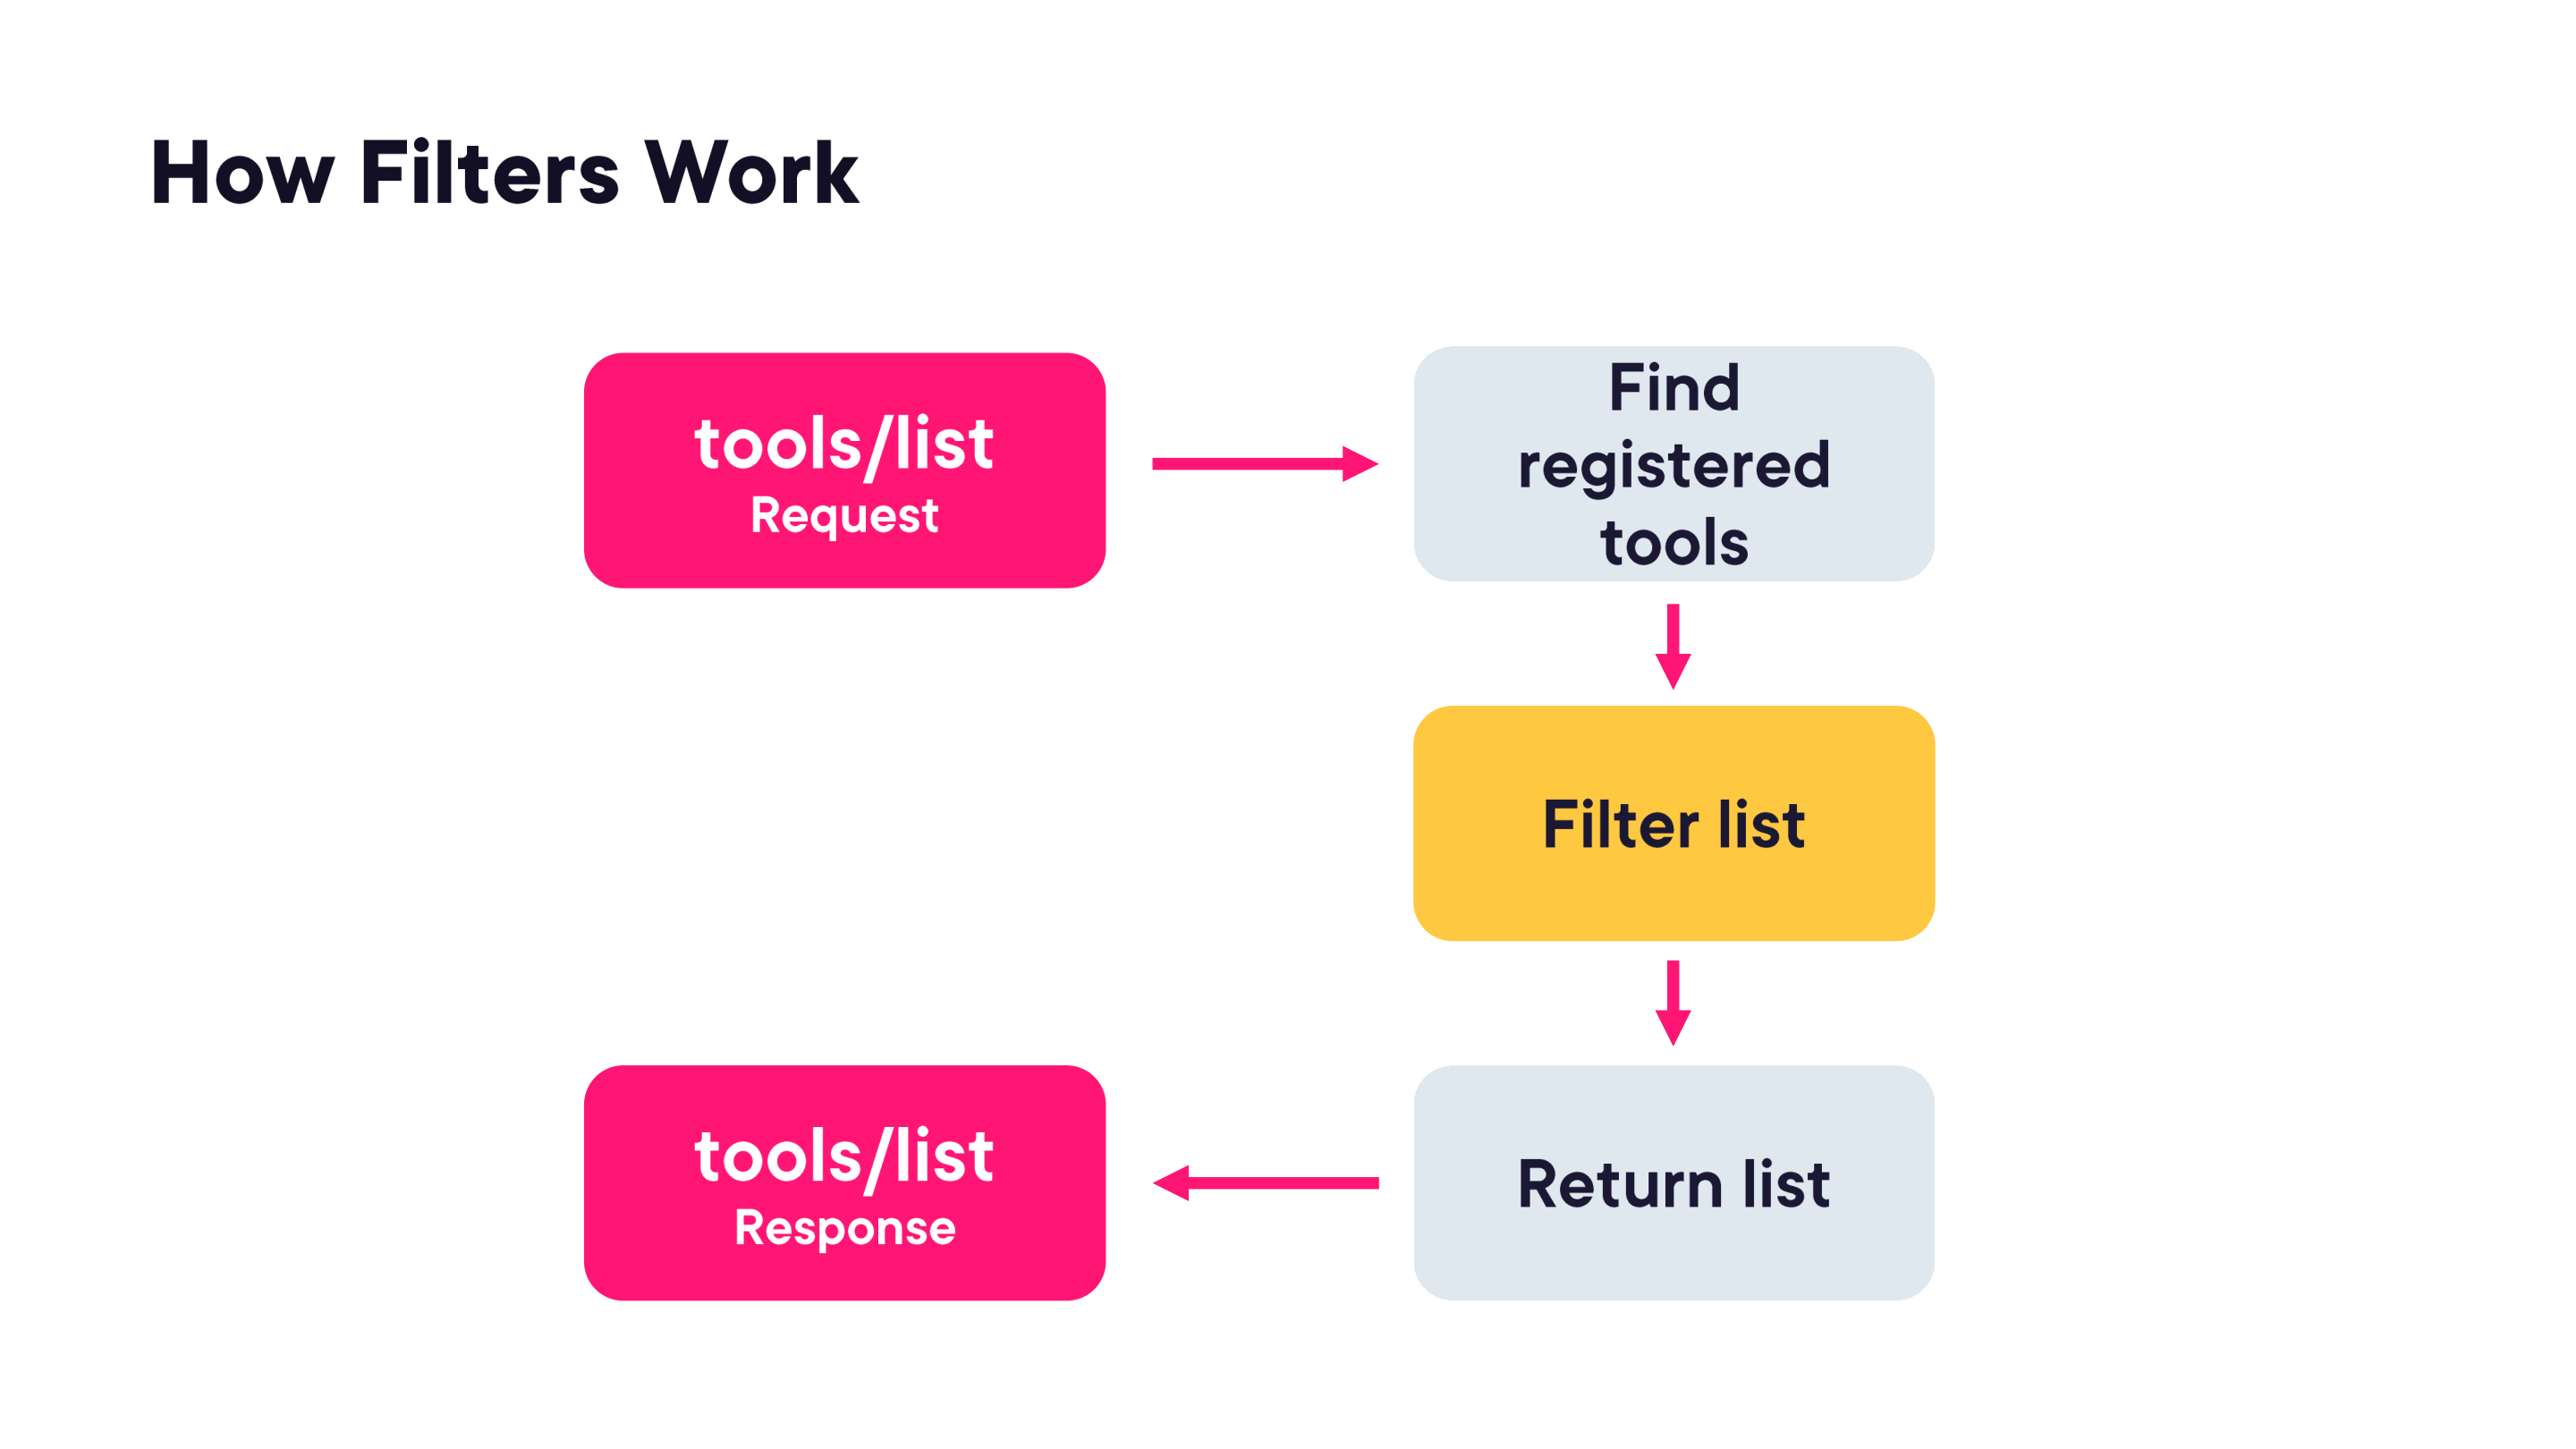

In [3]:
render_diagram(Path("assets/02-filter-request-pipeline-with-filter.png"))

#### Filtering by SDK

Each SDK exposes filters differently:

| SDK | API |
|---|---|
| C# | `WithMessageFilters` → `AddIncomingFilter` / `AddOutgoingFilter` |
| Python (FastMCP) | `add_middleware` / `on_request` / `on_call_tool` |
| TypeScript | Custom — wrap handlers with function composition or override `setRequestHandler` |

**C# — incoming filter:**

```csharp
services.AddMcpServer()
    .WithMessageFilters(messageFilters =>
    {
        messageFilters.AddIncomingFilter(next => async (context, cancellationToken) =>
        {
            var logger = context.Services?.GetService<ILogger<Program>>();
            if (context.JsonRpcMessage is JsonRpcRequest request)
            {
                logger?.LogInformation("Request: {Method}", request.Method);
            }
            return await next(context, cancellationToken);
        });
    });
```

**Python (FastMCP) — middleware:**

```python
from fastmcp import FastMCP
from fastmcp.server.middleware import Middleware, MiddlewareContext

class LoggingMiddleware(Middleware):
    async def on_message(self, context: MiddlewareContext, call_next):
        print(f"→ {context.method}")
        result = await call_next(context)
        print(f"← {context.method}")
        return result

mcp = FastMCP("MyServer")
mcp.add_middleware(LoggingMiddleware())
```

**TypeScript — function composition (simplest approach):**

```typescript
const server = new McpServer({ name: "Filter Demo", version: "1.0.0" });

const withLogging = (handler) => {
  return async (params, extra) => {
    console.error("Handler request");
    const response = await handler(params, extra);
    console.error("Handler response");
    return response;
  };
}

server.registerTool("test", {}, withLogging(async (params, extra) => {
    return { content: [{ type: "text", text: "A test tool call" }] }
}));
```

> **Tradeoff:** Function composition is simple but requires you to remember to wrap every handler. It only works for `registerTool`, `registerPrompt`, and `registerResource`.

**TypeScript — middleware pipeline (advanced):**

Override `setRequestHandler` to inject a reusable middleware chain:

```typescript
const originalSetRequestHandler = server.server.setRequestHandler.bind(server.server);

server.server.setRequestHandler = (schema, handler) => {
  return originalSetRequestHandler(schema, async (request, extra) => {
    const startTime = Date.now();
    console.error(`[Middleware:Logging] → ${request.method} (request_id: ${extra.requestId})`);
    const result = await handler(request, extra);
    const duration = Date.now() - startTime;
    console.error(`[Middleware:Logging] ← ${request.method} completed in ${duration}ms`);
    return result;
  });
};
```

A builder API makes this ergonomic:

```typescript
withMiddleware(server)
  .use(logging())
  .use(caching())
  .use(allowedEnvs(environment, server));
```

The `MiddlewareHandler` type:

```typescript
type MiddlewareHandler = (
  request: JSONRPCRequest,
  extra: RequestHandlerExtra<ServerRequest, ServerNotification>,
  next: () => Promise<Result>,
) => Promise<Result>;
```

Example — caching middleware:

```typescript
export function caching(): MiddlewareHandler {
  const cache = new Map<string, { value: any; expires: number }>();
  return async (request, extra, next) => {
    if (request.method === "tools/call") {
      const params = request.params ?? {};
      delete params._meta;
      // Check cache, return cached value or call next and cache result
    }
    return next();
  };
}
```

Example — environment-based tool visibility (using tool `_meta` annotations):

```typescript
server.registerTool(
  "debug_logs",
  {
    description: "View detailed debug logs (development only)",
    inputSchema: { level: z.enum(["verbose", "debug", "trace"]).optional() },
    _meta: { allowedEnvs: ["development"] }
  },
  async ({ level }) => { /* ... */ }
);
```

### Completions

**Completions** are a standardized way for servers to offer autocomplete suggestions for the arguments of prompts and resource templates. When a user is filling in argument values, the server can return contextual suggestions.

Completions only *suggest* — they do not validate. The client is free to ignore suggestions and send any value.

#### Protocol messages

Request a completion (e.g. user has typed "py" for a `language` argument):

```json
{
  "jsonrpc": "2.0",
  "id": 1,
  "method": "completion/complete",
  "params": {
    "ref": { "type": "ref/prompt", "name": "code_review" },
    "argument": { "name": "language", "value": "py" }
  }
}
```

Response:

```json
{
  "jsonrpc": "2.0",
  "id": 1,
  "result": {
    "completion": {
      "values": ["python", "pytorch", "pyside"],
      "total": 10,
      "hasMore": true
    }
  }
}
```

The `context.arguments` field can carry previously-entered values so suggestions for later arguments can depend on earlier ones (e.g. filter frameworks based on the already-chosen language).

#### Completions by SDK

| SDK | API |
|---|---|
| C# | `.WithCompleteHandler(async (ctx, ct) => { ... })` |
| Python (low-level MCP) | `@mcp.completion()` |
| TypeScript | `completable(z.string(), value => [...])` wrapper |

**TypeScript — `completable` wrapper:**

```typescript
import { completable } from '@modelcontextprotocol/sdk/server/completable.js';

server.registerPrompt(
  'color_haiku',
  {
    description: "Write a haiku about a color",
    argsSchema: {
      color: completable(
        z.string().describe("Well-known CSS color name, hex, or color format"),
        (value) => {
          const wellKnownColors = Object.keys(colors);
          if (!value) return wellKnownColors;
          return wellKnownColors.filter(c => c.toLowerCase().startsWith(value.toLowerCase()));
        }
      ),
      mood: z.string().optional().describe("Mood of the haiku"),
    },
  },
  ({ color, mood }) => { /* ... */ }
);
```

> Completions do not validate — they only suggest values.

### Notifications

**Notifications** are one-way messages sent from server to client (or client to server). The receiver must not send a response. They are used for asynchronous events.

MCP defines these notification types:

- **Initialization** — connection lifecycle
- **Logging messages** — server-side log output to client
- **Cancellation** — cancel an in-flight request
- **List change notifications** — `notifications/tools/list_changed`, `notifications/prompts/list_changed`, `notifications/resources/list_changed`
- **Resource updated notifications** — `notifications/resources/updated` for subscribed resources
- **Progress notifications** — incremental updates for long-running operations

```json
{
  "jsonrpc": "2.0",
  "method": "notifications/tools/list_changed"
}
```

#### List change notifications with FastMCP

FastMCP's component visibility system automatically sends `list_changed` notifications when you enable or disable tools. No manual notification call is needed:

```python
from fastmcp import FastMCP, Context
from mcp.types import ToolAnnotations

mcp = FastMCP(name="Notifications Demo")

@mcp.tool(
    description="Restart the server",
    tags={"admin"},
    annotations=ToolAnnotations(destructiveHint=True),
)
def restart_server(server_id: str) -> str:
    return f"Restarting server {server_id}..."

@mcp.tool(description="Modify admin settings")
async def modify_admin_settings(ctx: Context) -> str:
    # Disable all admin-tagged tools for every session (server-wide)
    mcp.disable(tags={"admin"})

    # Or per-session only (FastMCP sends list_changed automatically):
    await ctx.disable_components(tags={"admin"})
    return "Admin settings modified. Admin tools disabled."
```

#### Resource subscriptions

Clients can subscribe to a resource and receive `notifications/resources/updated` when it changes. The server must declare the `subscribe` capability:

```typescript
const server = new McpServer(
  { name: "Resource Subscriptions Demo", version: "1.0.0" },
  { capabilities: { resources: { subscribe: true } } },
);

const subscriptions = new Set<string>();

server.server.setRequestHandler(SubscribeRequestSchema, async (request) => {
  subscriptions.add(request.params.uri);
  return {};
});

server.server.setRequestHandler(UnsubscribeRequestSchema, async (request) => {
  subscriptions.delete(request.params.uri);
  return {};
});
```

When a tool updates a resource, notify all subscribers:

```typescript
server.registerTool(
  "update_system_status",
  { inputSchema: { status: z.string() } },
  async ({ status }) => {
    systemState.status = status;
    const resourceUri = "system://status";
    // Notify all subscribed clients
    for (const sub of subscriptions) {
      if (sub === resourceUri) {
        await server.server.sendResourceUpdated({ uri: resourceUri });
      }
    }
    return { content: [{ type: "text", text: `Status updated to: ${status}` }] };
  }
);
```

#### Progress notifications

For long-running tools, send incremental progress updates using `ctx.report_progress()`:

```python
_DEPLOYMENT_STEPS = [
    "Validating configuration",
    "Pulling container image",
    "Provisioning infrastructure",
    "Starting containers",
    "Running health checks",
    "Updating DNS records",
    "Notifying monitoring system",
]

@mcp.tool(description="Run a simulated multi-step deployment with progress reporting")
async def run_deployment(environment: str, ctx: Context) -> str:
    for i, step in enumerate(_DEPLOYMENT_STEPS):
        await ctx.report_progress(
            progress=i,
            total=len(_DEPLOYMENT_STEPS),
            message=step,
        )
        await asyncio.sleep(1)
    return f"Deployment to {environment} complete."
```

Reference: [MCP Specification — Progress](https://modelcontextprotocol.io/specification/2025-11-25/basic/utilities/progress)

### Demo: Advanced Server Features

See [`01-advanced-server-demos/`](01-advanced-server-demos/) for full demo projects covering:

- **Module-1-filters** — Function composition and middleware pipeline in TypeScript
- **Module-1-completions** — Color name autocompletion using completable
- **Module-1-notifications** — List change, resource subscriptions, and progress notifications

**Running the FastMCP demos:**

```bash
# Create and activate a virtual environment (first time only)
python -m venv .venv
source .venv/bin/activate   # macOS/Linux
.venv\Scripts\activate      # Windows

pip install -r requirements.txt

# Run a demo directly
python src/01_list_changed.py

# Or launch MCP Inspector against a specific demo
npm run inspect1
```

## Module 02: Advanced Client Features

This module covers features that require a **stateful** MCP connection: roots (filesystem boundary declarations), elicitations (asking the user for input mid-request), and sampling (giving the server its own LLM reasoning capability).

### Stateless vs. Stateful MCP

**Stateless MCP** — the server does not maintain any state across requests. Every request is isolated. In practice this means no persistent connection to the MCP client.

**Stateful MCP** — the server maintains session state across requests and keeps a persistent two-way connection to the client.

| | Stateless | Stateful |
|---|---|---|
| Memory | Simple, memory-efficient | Maintains session state |
| Hosting | Serverless-friendly | Needs always-on hosting |
| Communication | One-way to client | Two-way with client |
| Features | — | Enables elicitations and sampling |

> An HTTP transport MCP server can be stateless or stateful, but **STDIO is always stateful**.

#### Making HTTP transport stateful

A common pattern: keep the MCP server itself stateless but put a stateful proxy in front of it. The proxy tracks sessions and connects to shared storage.

> Note: even with this pattern, a stateless HTTP server still cannot support elicitations or sampling — those require a real stateful server.


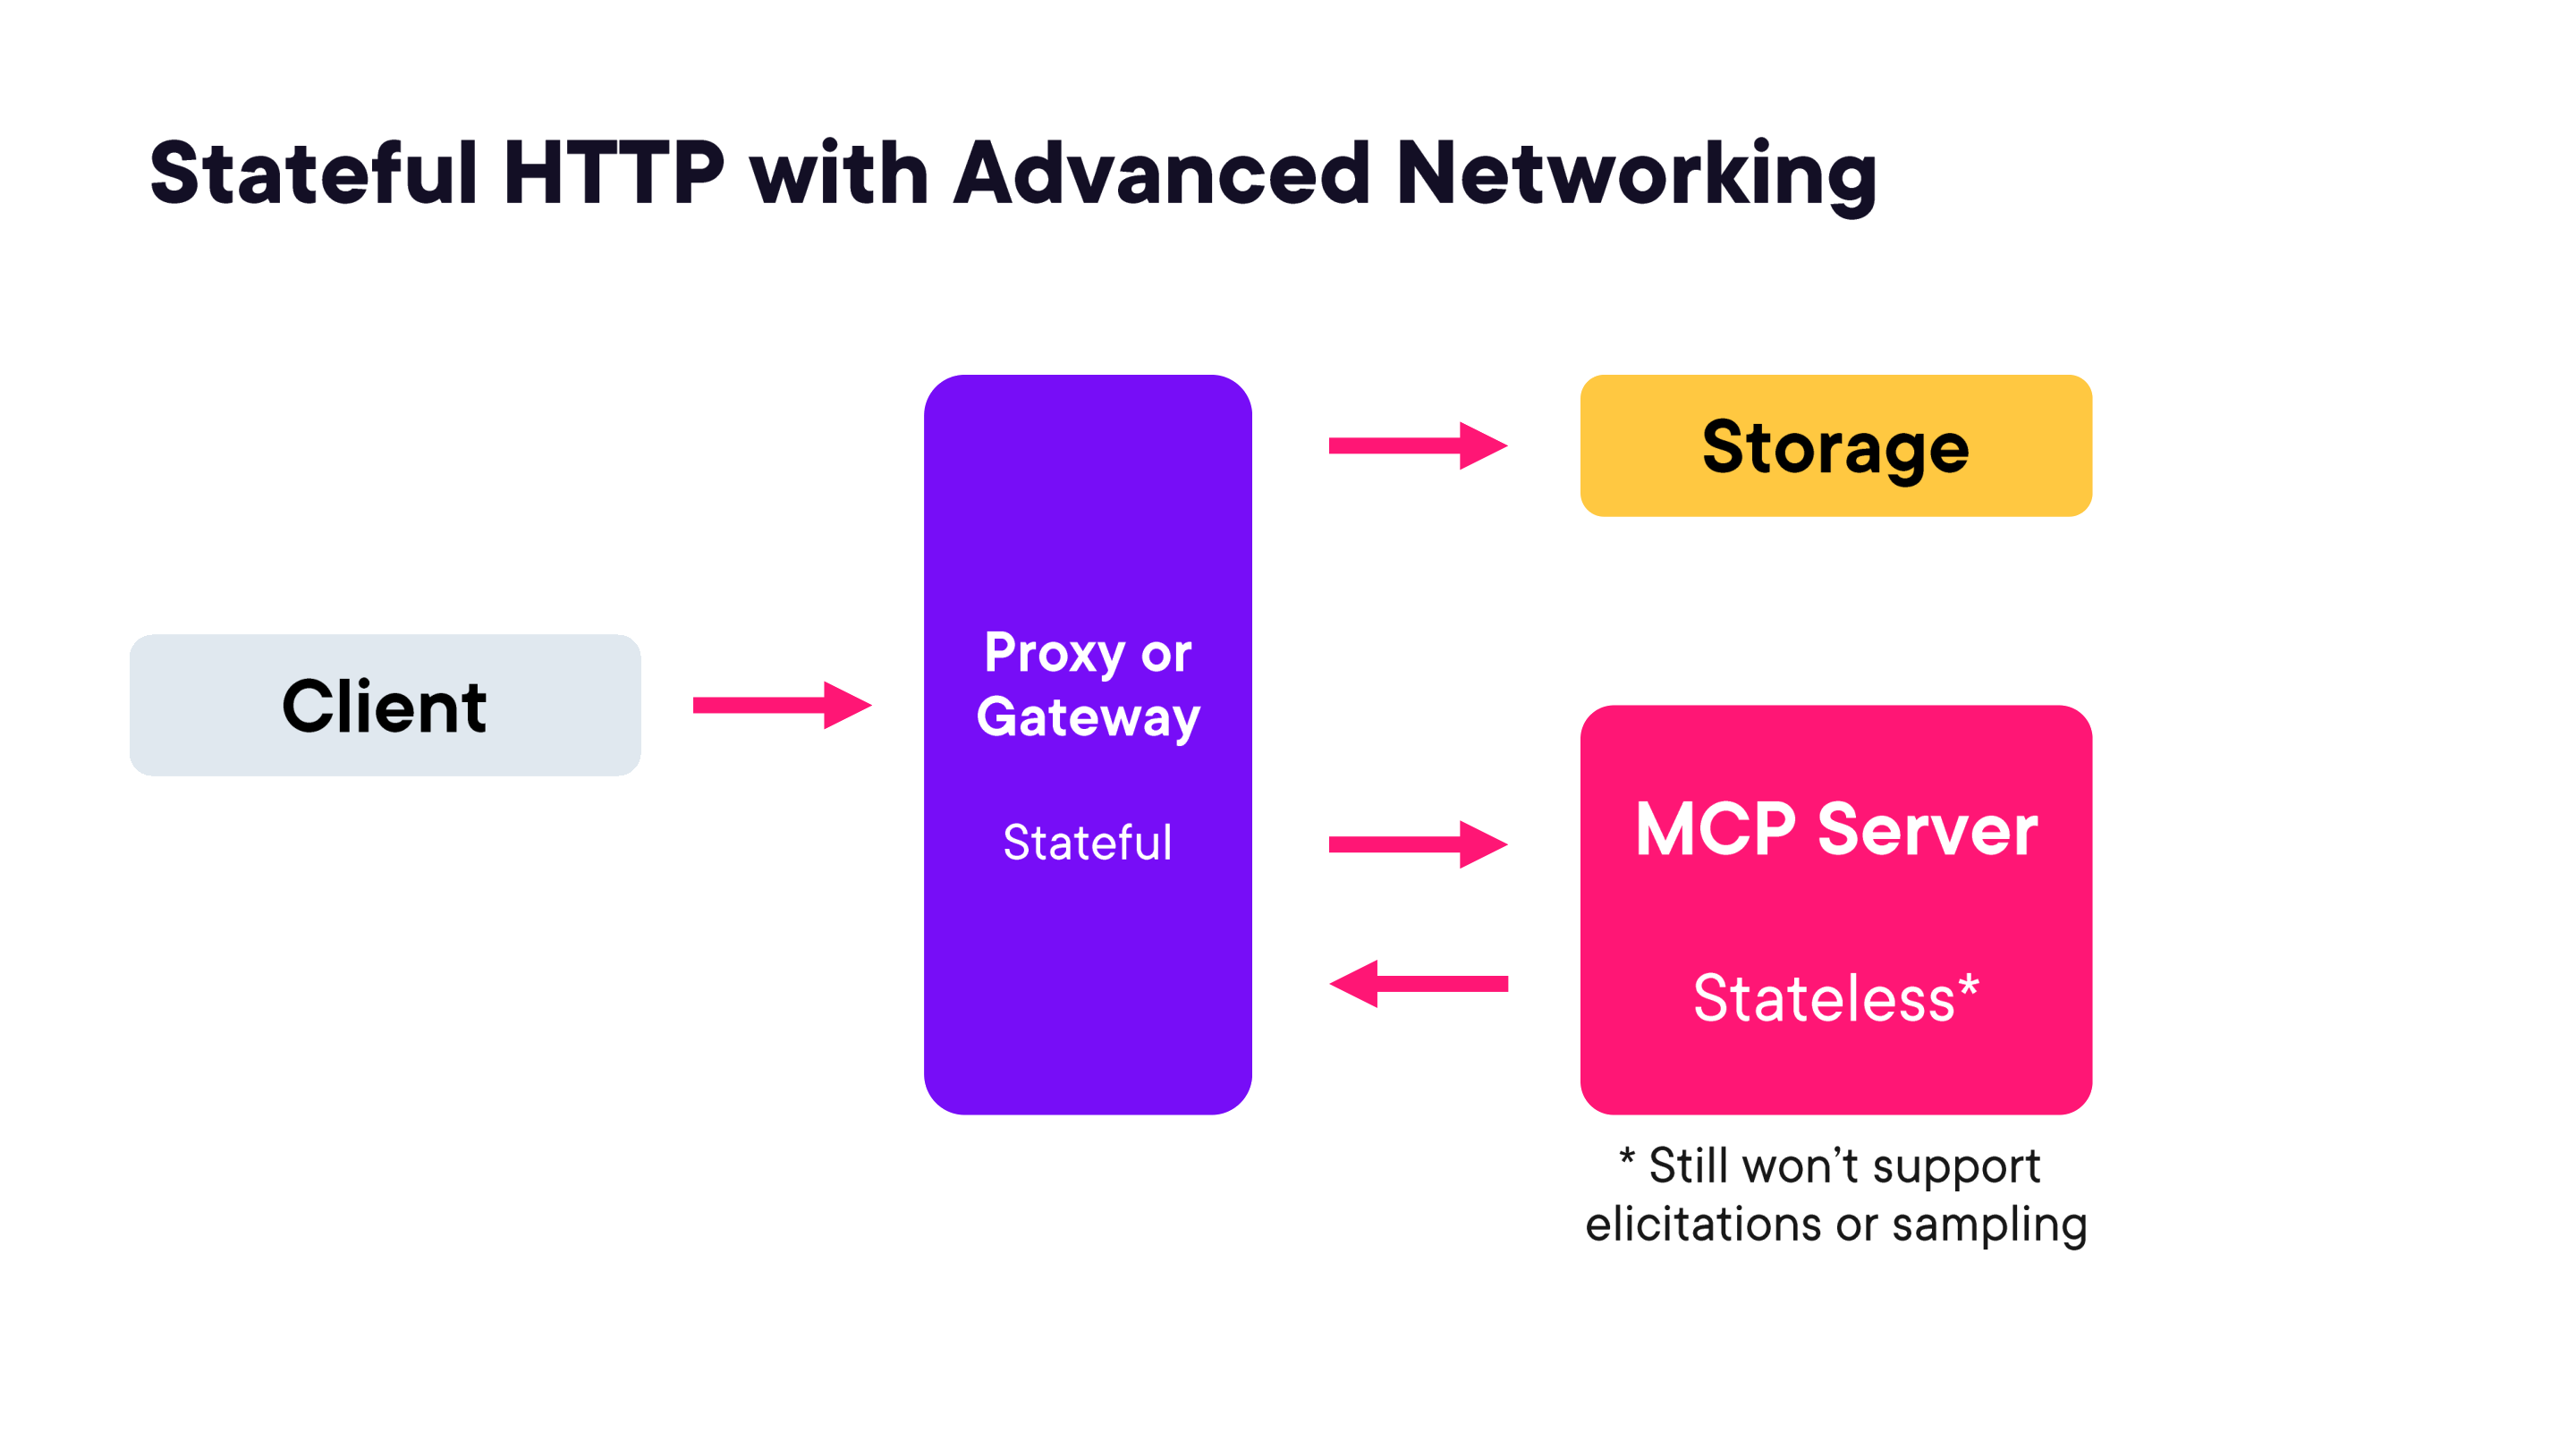

In [4]:
render_diagram(Path("assets/03-stateful-http-architecture.png"))

### Roots

**Roots** define filesystem boundaries the client is willing to expose to an MCP server. They:
- Apply only to local (STDIO) MCP servers
- Must use the `file://` URI scheme
- Allow servers to listen for changes when the user adds/removes workspace folders

Typical use cases: developer tools, coding agents that need to read/write project files.

**Client capability declaration:**

```json
{
  "capabilities": {
    "roots": { "listChanged": true }
  }
}
```

**Protocol messages:**

```json
// Server requests root list
{ "jsonrpc": "2.0", "id": 1, "method": "roots/list" }

// Client responds
{
  "jsonrpc": "2.0", "id": 1,
  "result": {
    "roots": [{ "uri": "file:///home/user/projects/myproject", "name": "My Project" }]
  }
}

// Client notifies server when roots change
{ "jsonrpc": "2.0", "method": "notifications/roots/list_changed" }
```

Reference: [MCP Specification — Roots](https://modelcontextprotocol.io/specification/2025-11-25/client/roots)

### Elicitations

**Elicitations** allow the server to ask the user for additional input during a tool call. There are two modes:

- **Form-based** — display form elements to collect structured input (not for sensitive data)
- **URL-based** — redirect the user to a URL for complex interactions like payments or OAuth

**Form-based elicitation request:**

```json
{
  "jsonrpc": "2.0", "id": 1,
  "method": "elicitation/create",
  "params": {
    "mode": "form",
    "message": "Please provide your GitHub username",
    "requestedSchema": {
      "type": "object",
      "properties": { "name": { "type": "string" } },
      "required": ["name"]
    }
  }
}
```

**URL-based elicitation request** (e.g. EULA acceptance, API key entry):

```json
{
  "jsonrpc": "2.0", "id": 3,
  "method": "elicitation/create",
  "params": {
    "mode": "url",
    "elicitationId": "550e8400-e29b-41d4-a716-446655440000",
    "url": "https://mcp.example.com/ui/set_api_key",
    "message": "Please provide your API key to continue."
  }
}
```

After the user completes a URL-based elicitation, the server can optionally be notified:

```json
{
  "jsonrpc": "2.0",
  "method": "notifications/elicitation/complete",
  "params": { "elicitationId": "550e8400-e29b-41d4-a716-446655440000" }
}
```

If a URL-based elicitation is required before a tool can run, the server returns a specific error code `-32042` (`URL_ELICITATION_REQUIRED`) with the elicitation details in the error data.

### Sampling

**Sampling** gives the MCP server its own LLM reasoning capability by delegating to the *client's* LLM. The server sends a `sampling/createMessage` request, and the client uses its connected AI model to produce a response.

**Use cases without tool use:**
- Summarize provided context
- Generate audio/video descriptions from context
- Delegate reasoning to another MCP server

**Use cases with tool use:**
- Multi-step workflows where the LLM decides the next step
- Offload reasoning tasks from the main agent

> Sampling is for adding reasoning capability **to the server** — not for the client.

**Sampling request:**

```json
{
  "jsonrpc": "2.0", "id": 1,
  "method": "sampling/createMessage",
  "params": {
    "messages": [
      { "role": "user", "content": { "type": "text", "text": "What is the capital of France?" } }
    ],
    "modelPreferences": {
      "hints": [{ "name": "claude" }],
      "intelligencePriority": 0.8,
      "speedPriority": 0.2
    },
    "maxTokens": 1024
  }
}
```

**Sampling request with tool use** (server provides tools the LLM can call):

```json
{
  "jsonrpc": "2.0", "id": 1,
  "method": "sampling/createMessage",
  "params": {
    "tools": [
      {
        "name": "get_weather",
        "description": "Get current weather for a city",
        "inputSchema": {
          "type": "object",
          "properties": { "city": { "type": "string" } }
        }
      }
    ]
  }
}
```

**FastMCP client — implementing a sampling handler with Anthropic:**

```python
from fastmcp.client.sampling import SamplingMessage, SamplingParams
from fastmcp.client.sampling.handlers.anthropic import AnthropicSamplingHandler

class LoggingAnthropicHandler(AnthropicSamplingHandler):
    async def __call__(self, messages, params, context):
        tools = getattr(params, "tools", None) or []
        print(f"[sampling] sending {len(messages)} messages, {len(tools)} tools")
        return await super().__call__(messages, params, context)

handler = LoggingAnthropicHandler(default_model="claude-sonnet-4-5")

async with Client(
    server_url,
    sampling_handler=handler,
    sampling_capabilities=SamplingCapability(tools=SamplingToolsCapability()),
) as client:
    result = await client.call_tool("plan_trip", {"destination": "Tokyo", "days": 3})
```

### Demo: Advanced Client Features

See [`01-advanced-server-demos/`](01-advanced-server-demos/) for the client feature demos:

- **Module-2-roots** — Scanning the filesystem using declared root boundaries
- **Module-2-elicitation** — Form-based and URL-based elicitation demos
- **Module-2-sampling** — Trip planner with and without tool use
- **Module-2-stateful** / **Module-2-stateless** — Cloudflare Agents SDK stateful HTTP server demo

**Running the sampling demo** (requires Anthropic API key):

```bash
# Terminal 1 — start the TypeScript MCP server
cd server && npm start

# Terminal 2 — run the Python sampling client
source .venv/bin/activate
python client/run_sampling_client.py probe
python client/run_sampling_client.py plan --destination tokyo --days 3
```

## Module 03: Custom MCP Clients

This module demonstrates how to build a fully custom MCP client in Python using FastMCP's `Client` class — connecting to a server, calling tools, reading resources, rendering prompts, and handling sampling.

### The Demo Server (CFP Manager)

The demo uses a **Call for Papers (CFP) management server** built with FastMCP. It exposes:

```python
mcp = FastMCP(
    name="CFP Manager",
    instructions=(
        "A Call for Papers management server. Use the available tools to submit "
        "and manage conference proposals, read proposal data via resources, and "
        "generate structured review prompts."
    ),
)
```

**Tools:**

```python
@mcp.tool
def submit_proposal(title: str, speaker: str, topic: str, abstract: str) -> Proposal:
    """Submit a new conference proposal."""
    proposal = Proposal(
        id=f"prop-{uuid.uuid4().hex[:6]}",
        title=title, speaker=speaker, topic=topic, abstract=abstract,
        status=ProposalStatus.PENDING,
    )
    _proposals[proposal.id] = proposal
    return proposal
```

**Resources:**

```python
@mcp.resource("cfp://proposals")
def list_proposals() -> str:
    """A JSON list of all submitted conference proposals."""
    return json.dumps([p.model_dump() for p in _proposals.values()], indent=2)

@mcp.resource("cfp://topics")
def list_topics() -> str:
    """A JSON list of accepted topic categories."""
    return json.dumps(TOPICS, indent=2)
```

**Prompts:**

```python
@mcp.prompt
def review_proposal(title: str, abstract: str) -> str:
    """Generate a structured review prompt for evaluating a conference proposal."""
    return f"""You are an experienced program committee member reviewing a conference proposal.
Evaluate the following proposal and provide a structured review.

## Proposal
**Title:** {title}
**Abstract:** {abstract}

Evaluate on: fit, originality, and clarity."""
```

Inspect the server from the command line:

```bash
python server.py
fastmcp inspect server.py
fastmcp list server.py --input-schema
fastmcp list server.py --output-schema
fastmcp call server.py get_proposal proposal_id=prop-001
```

### Building a Custom Client

FastMCP's `Client` class provides a full async MCP client. Pass a server script path (for STDIO) or a URL (for HTTP):

```python
import asyncio
from fastmcp import Client

async def main() -> None:
    client = Client("server.py")
    async with client:
        await client.ping()
        print("Connected.")

asyncio.run(main())
```

#### Calling Tools

```python
async def demo_tools(client: Client) -> None:
    # Discover available tools
    tools = await client.list_tools()
    for tool in tools:
        print(f"  • {tool.name}: {tool.description}")

    # Submit a proposal
    result = await client.call_tool(
        "submit_proposal",
        {
            "title": "Observability-Driven Development",
            "speaker": "Dana Kim",
            "topic": "Developer Experience",
            "abstract": "What if observability wasn't an afterthought? ...",
        },
    )
    proposal = result.data
    print(f"Created: {proposal}")

    # Fetch it back
    result = await client.call_tool("get_proposal", {"proposal_id": proposal.id})
    fetched = result.data

    # Update its status
    result = await client.call_tool(
        "update_proposal_status",
        {"proposal_id": proposal.id, "status": "accepted"},
    )
```

#### Reading Resources

```python
from mcp.types import TextResourceContents

async def demo_resources(client: Client) -> None:
    resources = await client.list_resources()

    content = await client.read_resource("cfp://proposals")
    assert isinstance(content[0], TextResourceContents)
    proposals = json.loads(content[0].text)

    content = await client.read_resource("cfp://topics")
    topics = json.loads(content[0].text)
```

#### Reading Prompts

```python
async def demo_prompts(client: Client) -> None:
    prompts = await client.list_prompts()

    result = await client.get_prompt("review_proposal", {"title": "...", "abstract": "..."})
    for message in result.messages:
        print(f"\n[{message.role}]\n{message.content.text}")
```

#### Client Sampling with Anthropic

To use sampling, provide a `sampling_handler` when constructing the client:

```python
from fastmcp.client.sampling.handlers.anthropic import AnthropicSamplingHandler

handler = AnthropicSamplingHandler(default_model="claude-sonnet-4-5")

async with Client(
    server_url,
    sampling_handler=handler,
    sampling_capabilities=SamplingCapability(tools=SamplingToolsCapability()),
) as client:
    result = await client.call_tool("plan_trip", {"destination": "Tokyo", "days": 3})
```

Set `ANTHROPIC_API_KEY` in a `.env` file before running:

```bash
ANTHROPIC_API_KEY=sk-...
```

### Demo: Custom MCP Clients

See [`01-advanced-server-demos/`](01-advanced-server-demos/) for:

- **Module-3-basic-client** — Minimal FastMCP client: ping, list tools/resources/prompts, call tool
- **Module-3-sampling** — Full sampling client with Anthropic handler and tool-use support

**Setup:**

```bash
python -m venv .venv
source .venv/bin/activate
pip install -r requirements.txt

# Run the basic client
python client.py

# Run with VS Code
# Open the folder in VS Code and use the integrated terminal
```

## Module 04: Agentic Workflows with MCP

This module covers building full agentic workflows using Cloudflare Workers AI and the Agents SDK — including integrating traditional REST APIs via MCP, using Code Mode to reduce tool-call overhead, and orchestrating multi-step durable workflows from an AI chat agent.

### What Makes an Agentic Workflow?

An **agentic workflow** involves LLM-based reasoning and task execution. Steps are typically arranged in a directed graph using nodes.

An AI agent combines three capabilities:

| Component | Role |
|---|---|
| **Context** (Knowledge) | What the agent knows — data, documents, memory |
| **Reason** (Task Planning) | LLM-based planning and decision making |
| **Act** (Tool Use) | Executing actions via tools |

MCP directly maps onto this model: resources provide context, tools provide actions, and prompts guide reasoning. **An MCP server just becomes another toolchain for an agent** — and an agent can also be an MCP server itself.

#### Ways to Create AI Agents

| Approach | Flexibility | Examples |
|---|---|---|
| Managed | Least flexible | Claude Skills |
| Low/No-Code | Middle | Zapier Agents (supports MCP) |
| From Scratch | Most flexible | Cloudflare Agents SDK |

Reference: [Cloudflare Agents](https://developers.cloudflare.com/agents/)

### Integrating a Traditional REST API via MCP

There are two strategies for integrating an existing REST API into an agent:

- **Write fetch logic in your agent** — use an SDK client or raw HTTP requests directly
- **Wrap it as an MCP server** — expose API endpoints as tools; reusable across agents

> You'll usually get better results if you design a purpose-built MCP server for an API rather than exposing every endpoint verbatim.

**Naïve wrapping** — one MCP tool per API endpoint:

For a query like "Find the best restaurant in Minneapolis", a naïve wrapper makes 1 search call and then 10 separate location detail calls — an AI agent has to orchestrate each one individually.


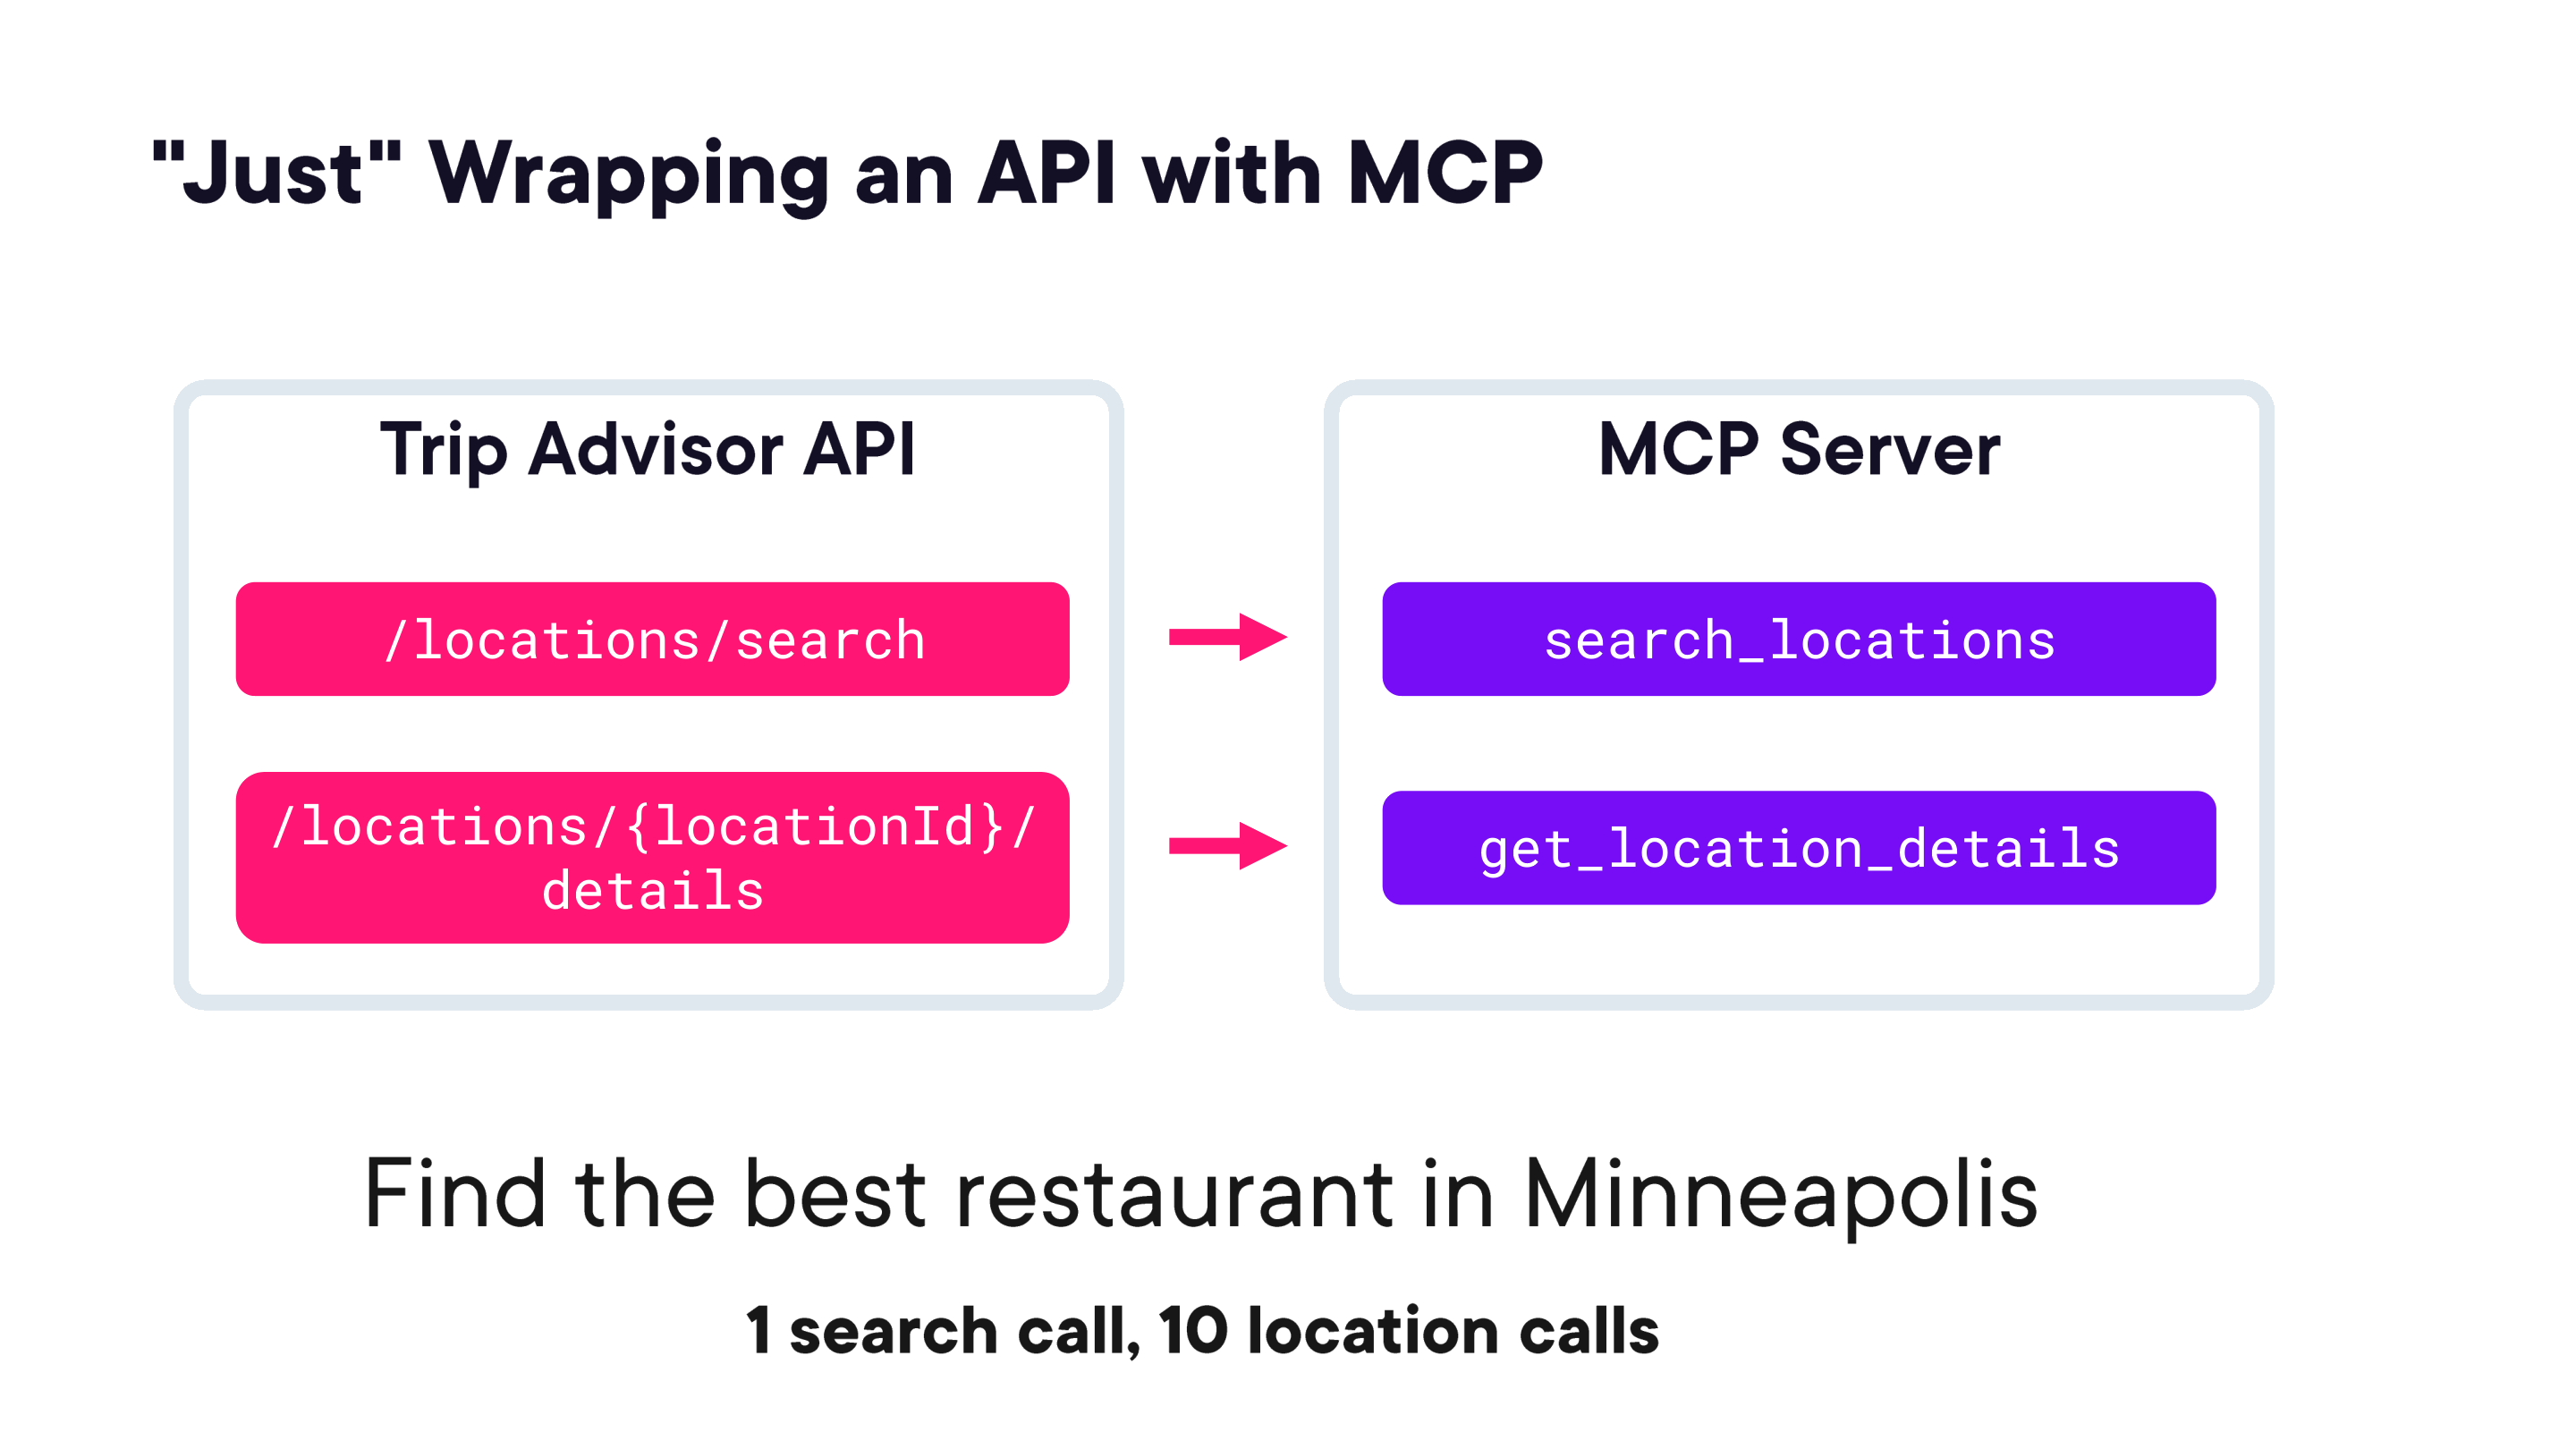

In [5]:
render_diagram(Path("assets/05-api-wrapping-flow.png"))

#### Cloudflare Code Mode

When an MCP server exposes many fine-grained tools, an agent can suffer **choice paralysis**. Cloudflare's Code Mode solves this by replacing many individual tool calls with two meta-tools: `search` and `execute`.

Instead of the agent calling each API endpoint individually, it writes code that the `execute` tool runs in a sandboxed environment. This reduces 10 individual tool calls down to 2 `execute` calls for the same "Find the best restaurant in Minneapolis" query.


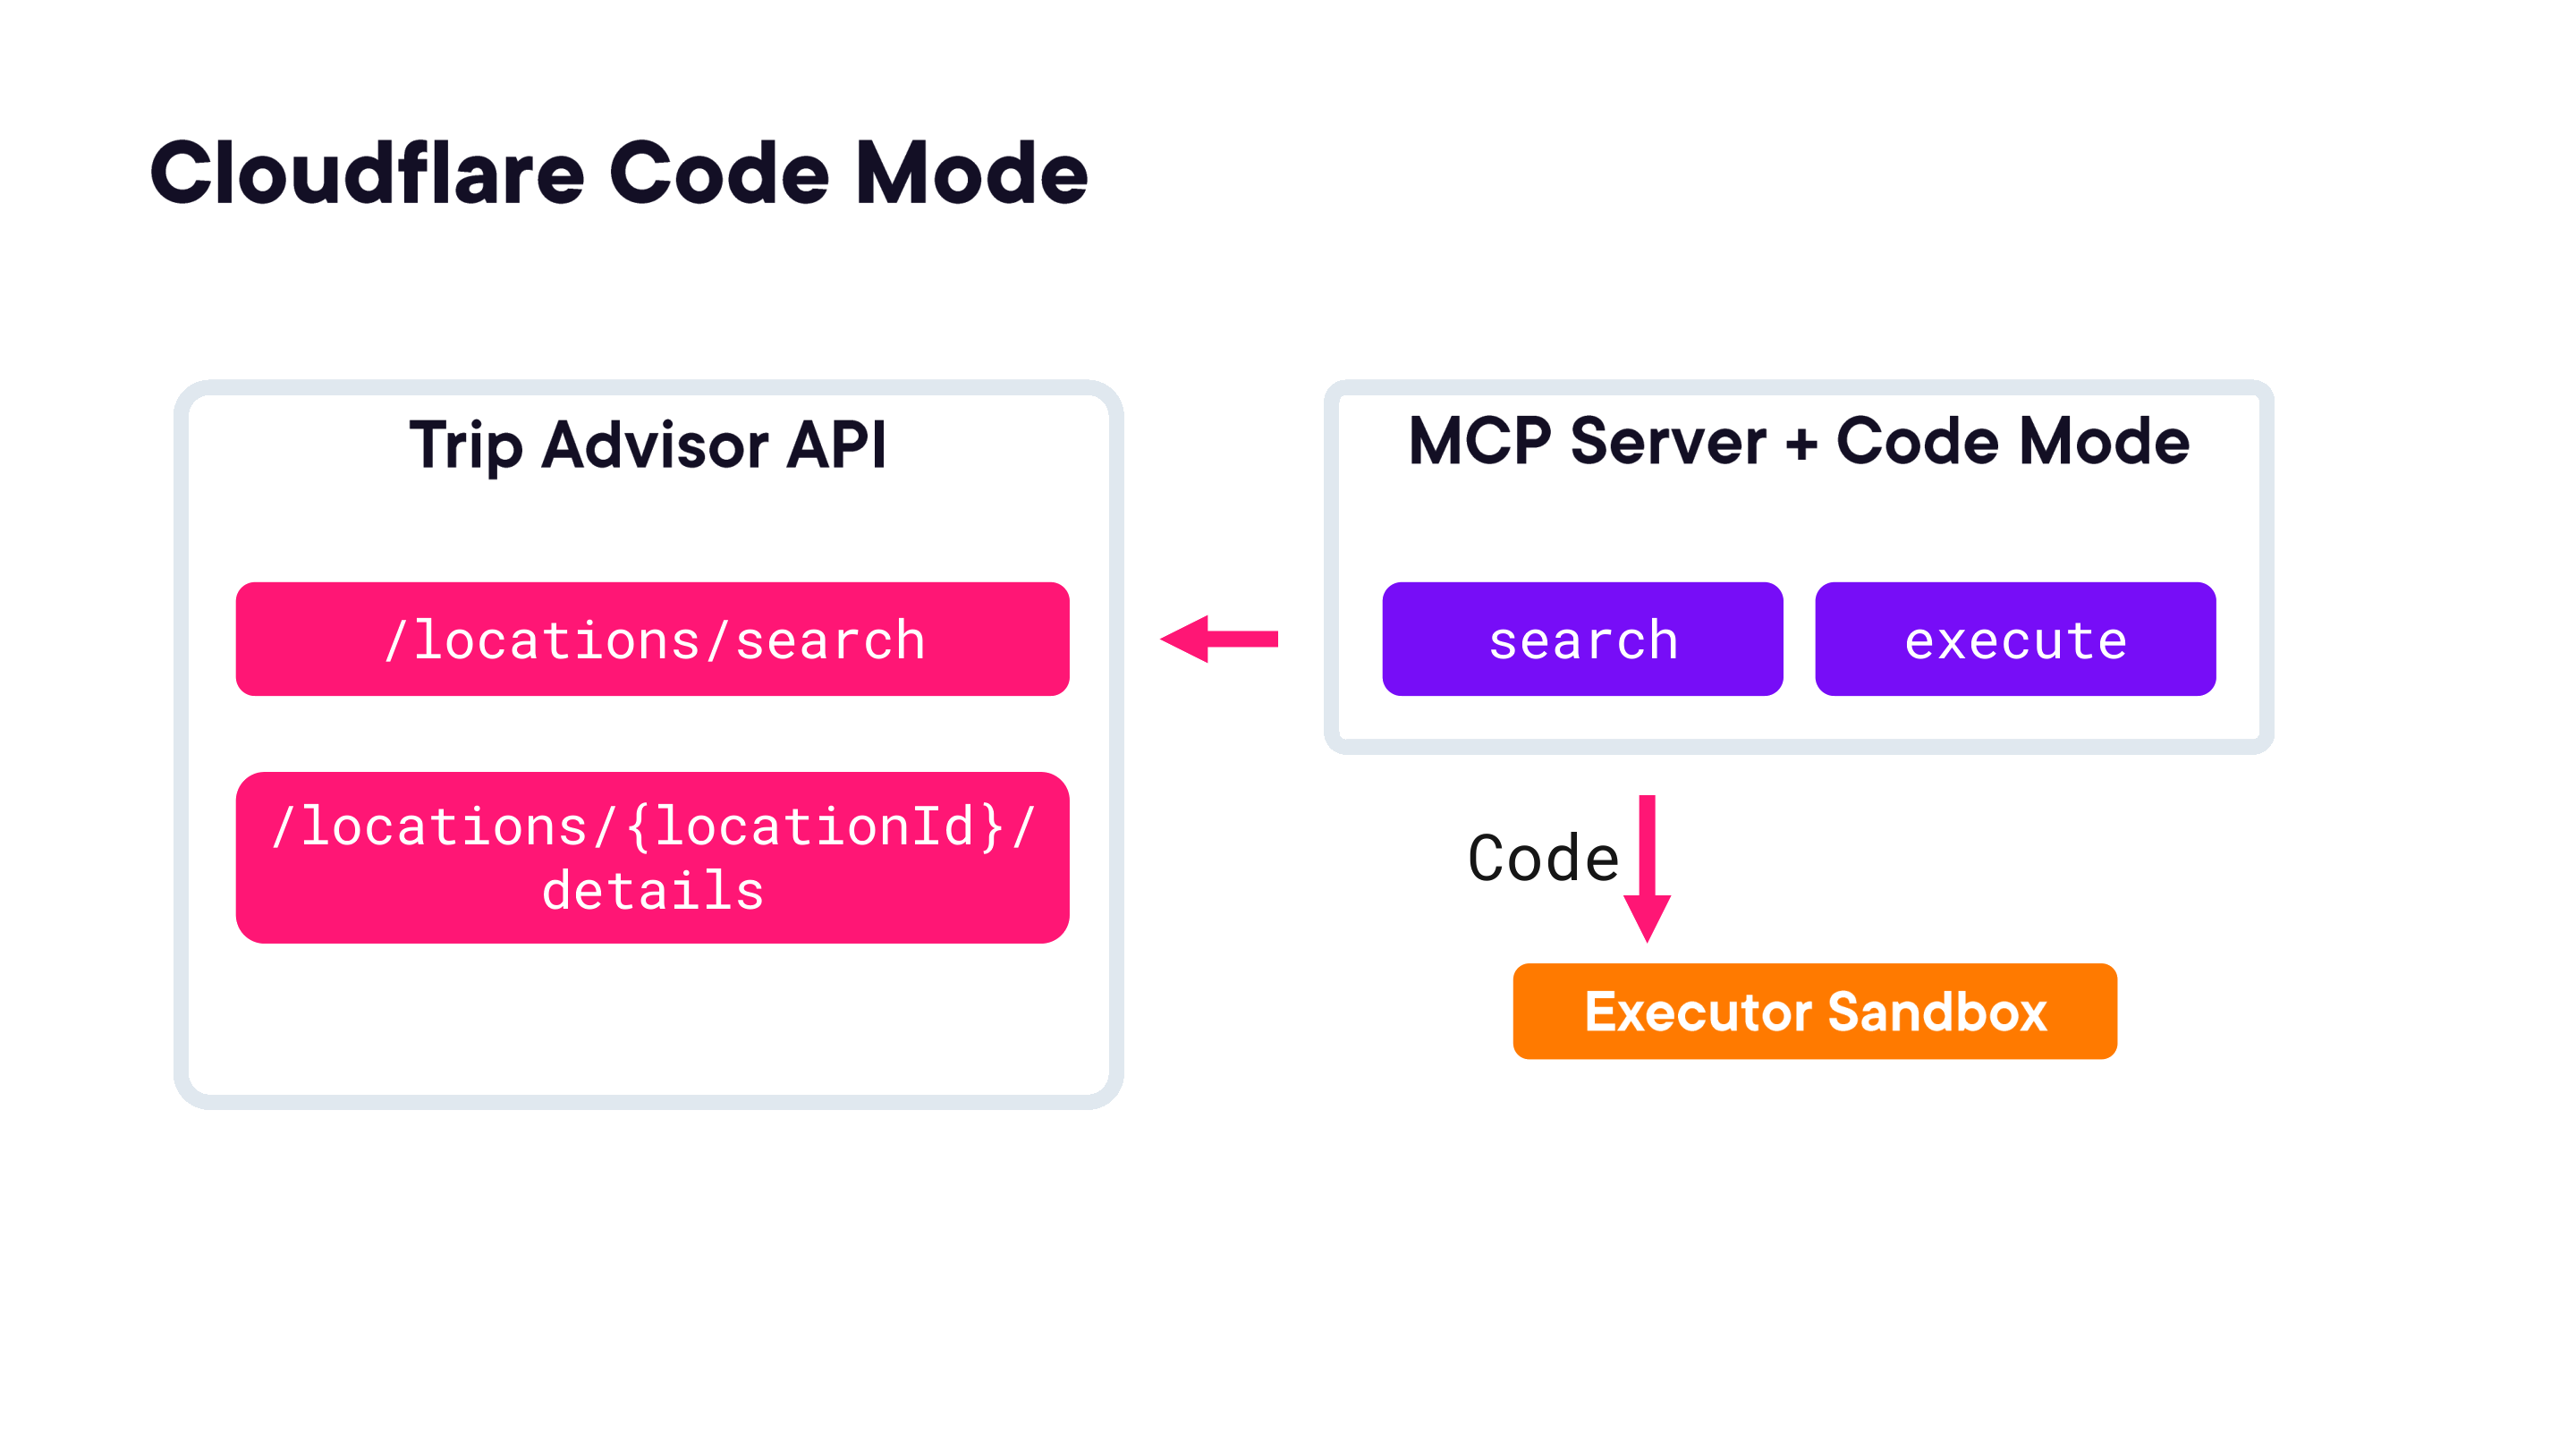

In [6]:
render_diagram(Path("assets/06-cloudflare-code-mode-flow.png"))

The agent writes code like this, which the `execute` tool runs in the sandboxed environment using RPC bindings back to the underlying API:

```typescript
async () => {
  const ids = ["444498", "2104112", "489548", "3984679", ...];
  const results = await Promise.all(
    ids.map(id => codemode.request({ method: "GET", path: `/location/${id}/details` }))
  );
  return results;
}
```

With RPC bindings, the sandbox calls back to the MCP server via the worker's `execute` binding rather than making outbound HTTP calls — reducing both latency and call count.


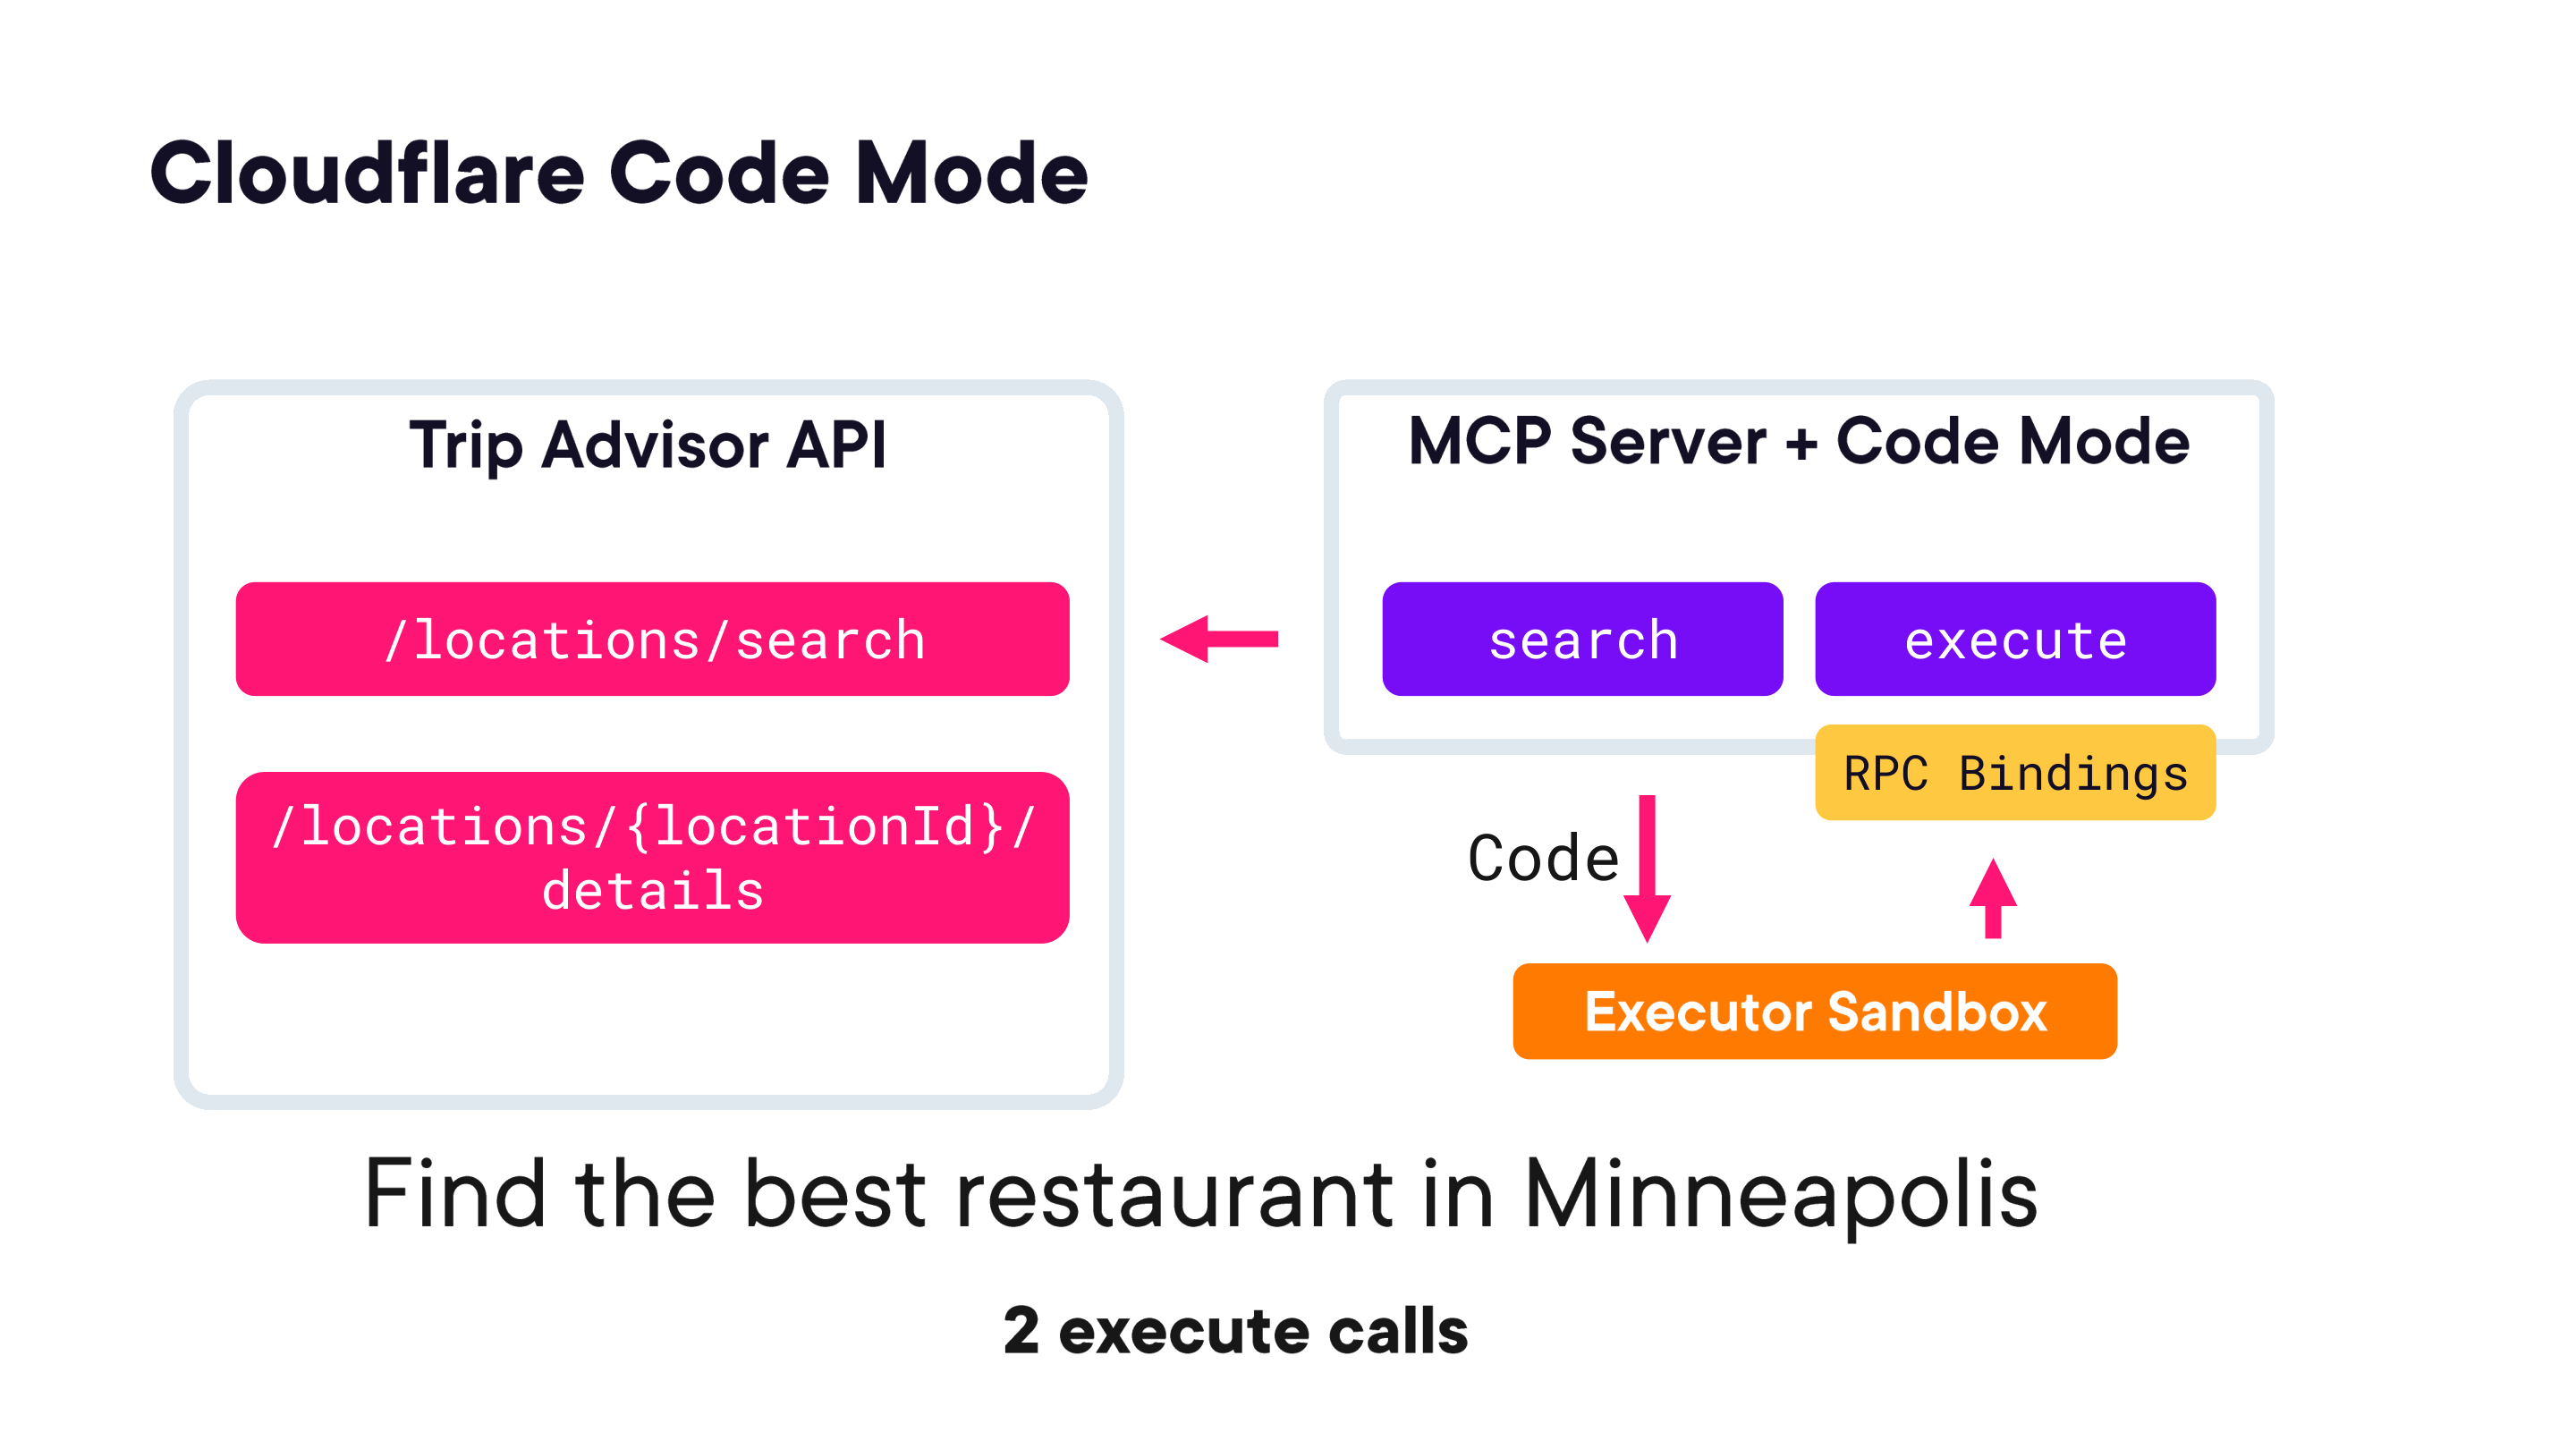

In [7]:
render_diagram(Path("assets/07-code-mode-with-rpc.png"))

**Generating an MCP server from an OpenAPI spec** using Code Mode:

```typescript
import { createMcpHandler } from "agents/mcp";
import { DynamicWorkerExecutor } from "@cloudflare/codemode";
import { openApiMcpServer } from "@cloudflare/codemode/mcp";
import spec from './tripadvisor-v1-spec.json';

export default {
  async fetch(request: Request, env: Env, ctx: ExecutionContext): Promise<Response> {
    const token = env.TRIP_ADVISOR_API_KEY;
    if (!token) return new Response("Missing API key", { status: 500 });

    const executor = new DynamicWorkerExecutor(env.CODE_EXECUTOR, { token });
    const handler = createMcpHandler(openApiMcpServer(spec, executor));
    return handler(request, env, ctx);
  }
};
```

Reference: [Cloudflare Code Mode](https://blog.cloudflare.com/code-mode/)

### The Travel Agent Architecture

The demo builds a complete travel agent running on Cloudflare Workers. The full architecture connects a client UI to a Cloudflare Worker that hosts both an MCP server and a stateful AI chat agent:


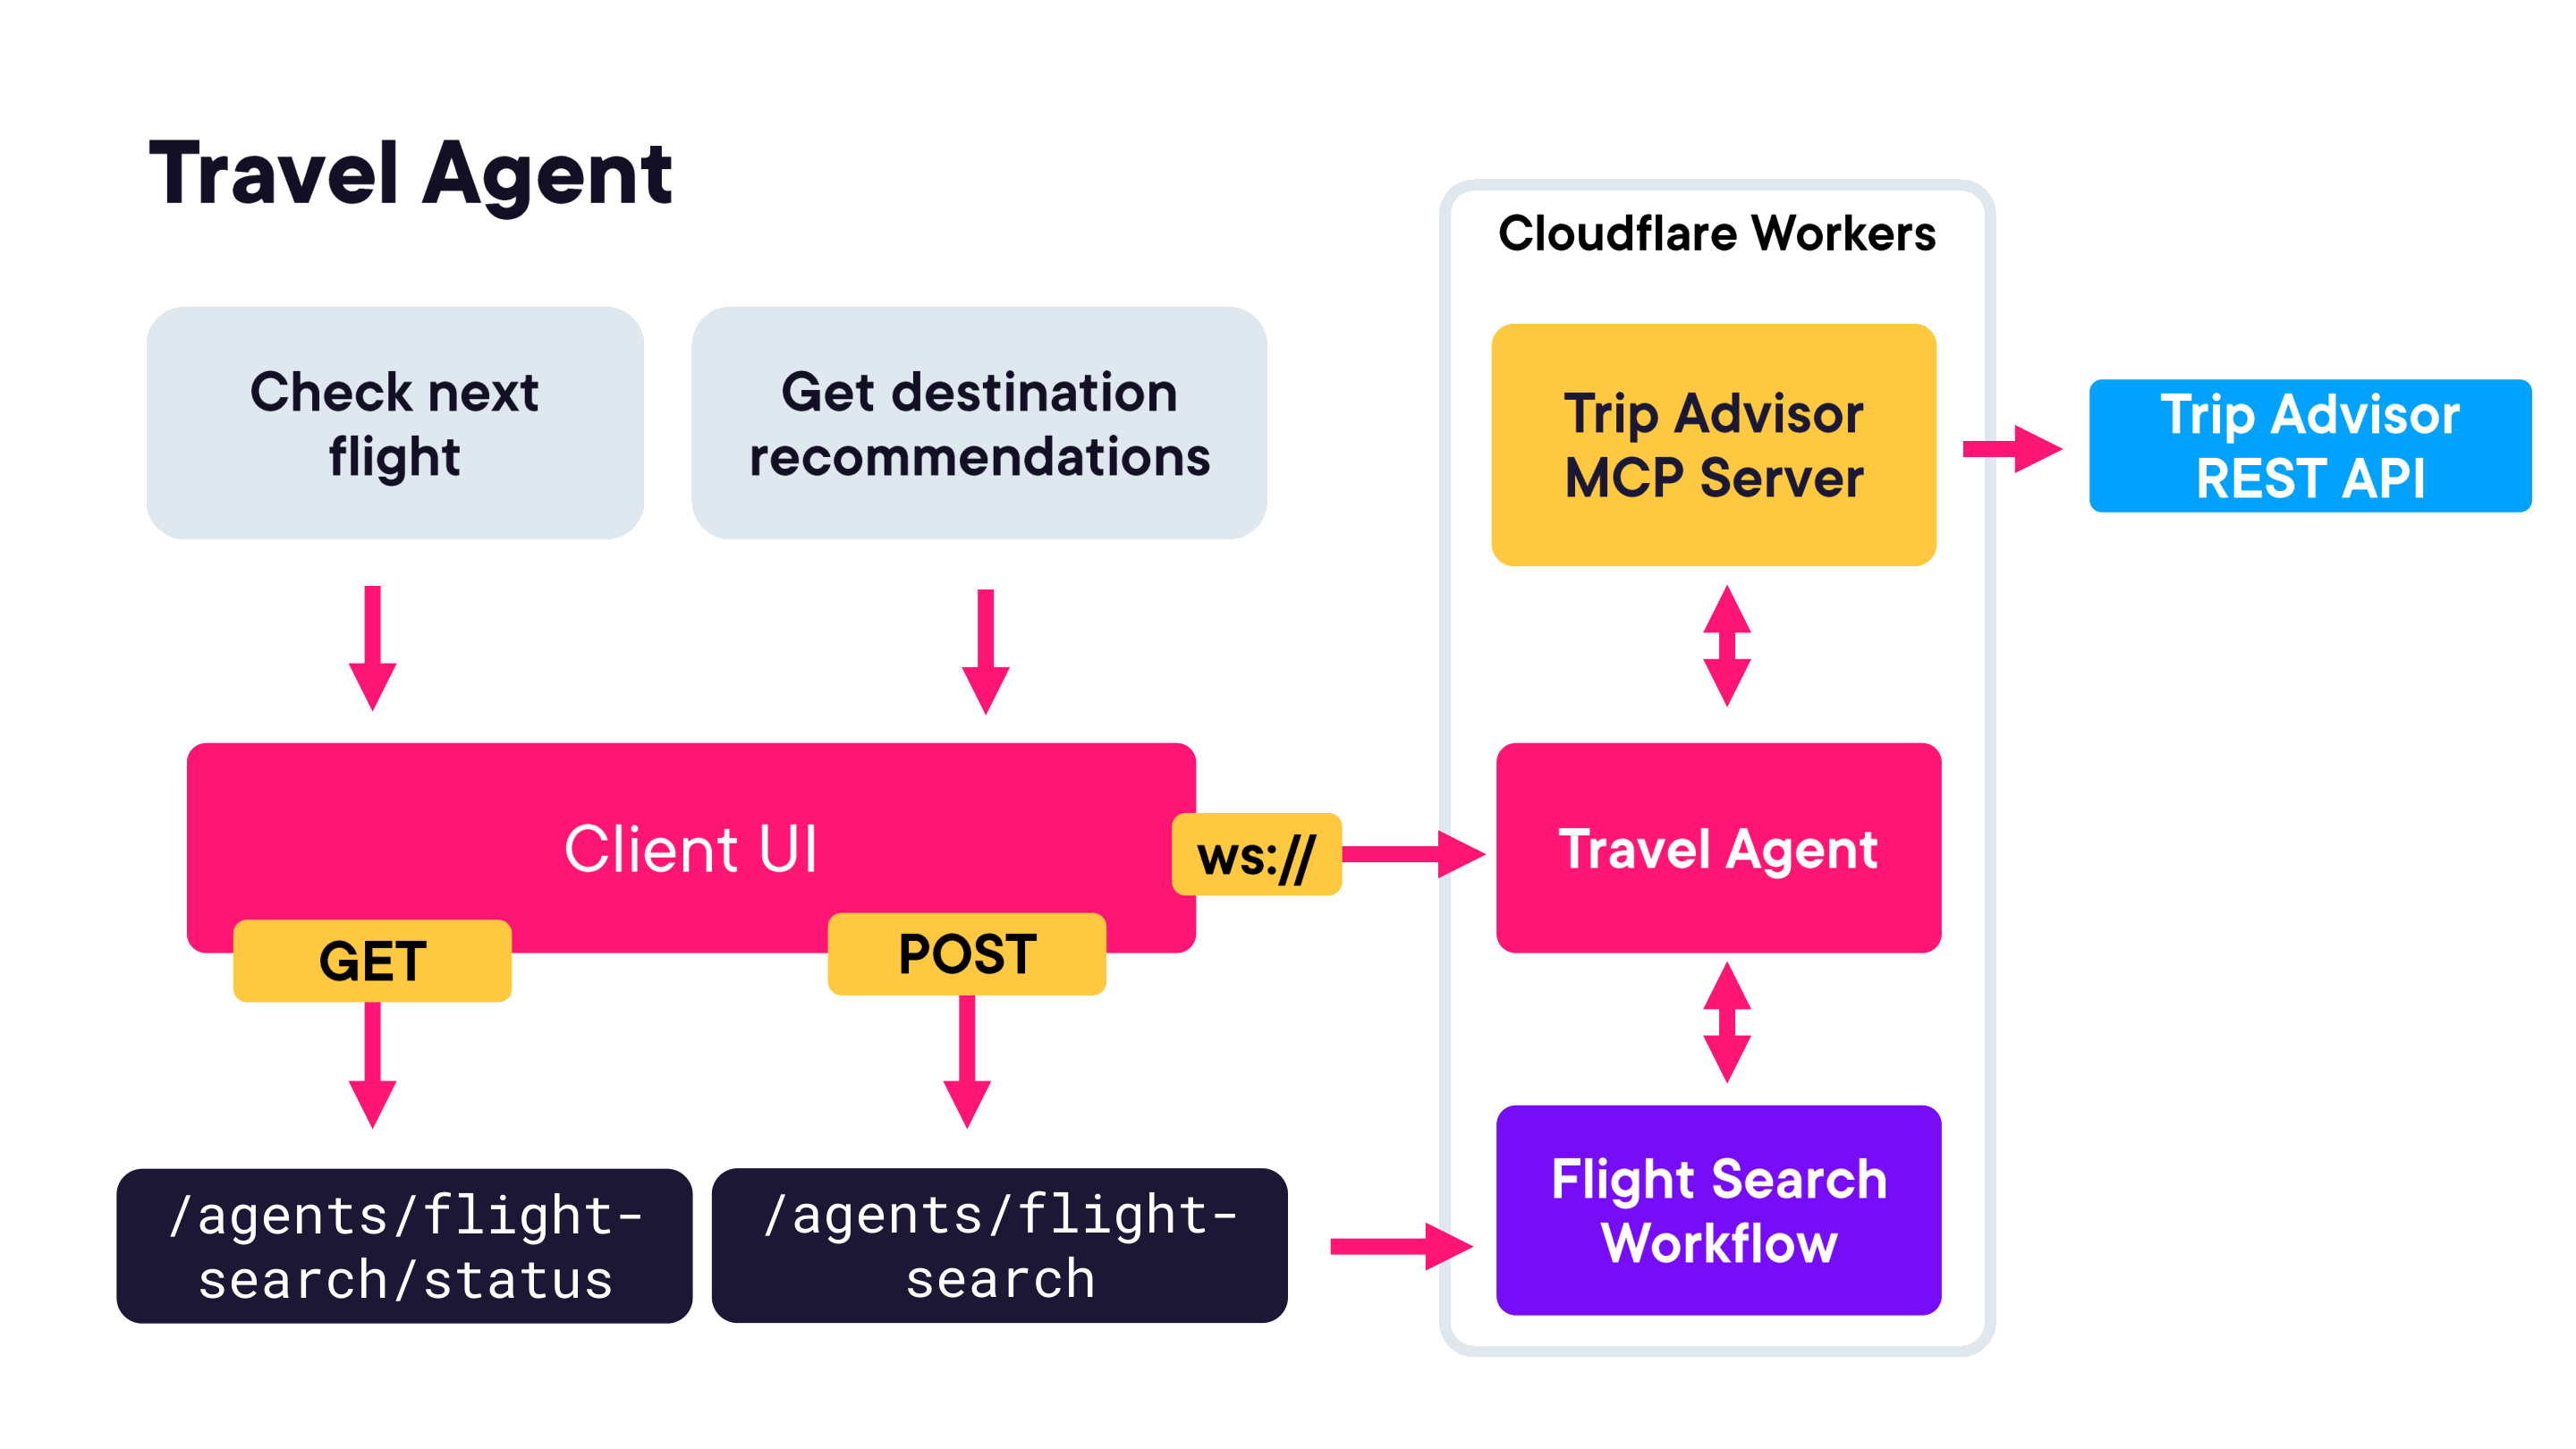

In [8]:
render_diagram(Path("assets/04-travel-agent-architecture.png"))

#### Building a Cloudflare AI Chat Agent

The `ChatAgent` extends Cloudflare's `AIChatAgent` and uses the Workers AI model via the Vercel AI SDK:

```typescript
import { streamText, convertToModelMessages, pruneMessages } from "ai";

export class ChatAgent extends AIChatAgent {
  // Wait for MCP server connections before handling messages
  waitForMcpConnections = true;

  onStart() {
    // Connect to the TripAdvisor MCP server
    this.addMcpServer("TripAdvisor", "http://127.0.0.1:8787/mcp");
  }

  async onChatMessage(_onFinish: unknown, options?: OnChatMessageOptions) {
    const workersai = createWorkersAI({ binding: this.env.AI });
    const result = streamText({
      model: workersai("@cf/zai-org/glm-4.7-flash"),
      messages: pruneMessages({ messages: await convertToModelMessages(this.messages) }),
      tools: {
        // Inject all tools from connected MCP servers
        ...this.mcp.getAITools(),
      },
    });
    return result;
  }
}
```

Start the agent:

```bash
npm start
```

Reference: [Cloudflare AI Chat Agent](https://developers.cloudflare.com/agents/api-reference/chat-agents/)

### Cloudflare Durable Workflows

Cloudflare Workflows provide durable, multi-step execution that survives restarts. Each step is checkpointed, so the workflow can resume from the last completed step.

```typescript
import { AgentWorkflow } from "agents/workflows";

const STEPS = [
  { name: "get_user_events",       task: "Get user's upcoming calendar events" },
  { name: "find_next_flight_event",task: "Find next event with flight information" },
  { name: "search_flight_status",  task: "Search for current status of the next flight" },
  { name: "report_flight_status",  task: "Report flight status to the user" },
];

export class FlightSearchWorkflow extends AgentWorkflow<TravelAgent, { task: string }> {
  async run(event: AgentWorkflowEvent<{ task: string }>, step: AgentWorkflowStep) {
    for (let stepIndex = 0; stepIndex < STEPS.length; stepIndex++) {
      const task = STEPS[stepIndex].task;

      // Report progress back to the agent and all connected WebSocket clients
      await this.reportProgress({
        step: task, status: "running",
        percent: stepIndex / STEPS.length,
        message: `Starting step: ${task}`,
      });

      // Each step.do() call is checkpointed — safe to restart
      await step.do(task, async () => {
        // LLM reasoning step (planning and tool calls happen here)
      });
    }
  }
}
```

#### Starting a workflow from an agent

```typescript
export class TravelAgent extends Agent {
  async startFlightSearch(task: string) {
    const instanceId = await this.runWorkflow("FLIGHT_SEARCH_WORKFLOW", { task });
    this.setState({ ...this.state, currentWorkflow: instanceId, status: "running" });
    return { instanceId };
  }

  async getFlightSearchStatus(instanceId: string) {
    return this.getWorkflowStatus("FLIGHT_SEARCH_WORKFLOW", instanceId);
  }

  // Called when workflow reports progress
  async onWorkflowProgress(workflowName, instanceId, progress) {
    this.broadcast(JSON.stringify({ type: "progress", instanceId, progress }));
  }

  // Called when workflow completes
  async onWorkflowComplete(workflowName, instanceId, result) {
    this.setState({ ...this.state, status: "complete" });
    this.broadcast(JSON.stringify({ type: "complete", instanceId, result }));
  }
}
```

#### Exposing the agent and workflow via HTTP

```typescript
export default {
  async fetch(request: Request, env: Env) {
    const url = new URL(request.url);
    // Route agent WebSocket/HTTP requests
    const response = await routeAgentRequest(request, env);
    if (response) return response;

    // REST endpoint to kick off a flight search
    if (request.method === "POST" && url.pathname === "/agents/flight-search") {
      // Starts the flight search workflow
    }
    // GET /agents/flight-search/status — poll workflow status
  }
};
```

The agent exposes a `getUserNextFlight` tool that orchestrates the workflow:

```typescript
getUserNextFlight: tool({
  description: "Get the user's next flight. Use this when you need to know upcoming travel plans.",
  inputSchema: z.object({}),
  execute: async () => {
    // Kicks off the durable flight-search workflow
    const instanceId = await agent.startFlightSearch("Find user's next flight");
    return { instanceId };
  },
}),
```

References:
- [Cloudflare Workflows](https://developers.cloudflare.com/workflows/)
- [Cloudflare Agents — Running Workflows](https://developers.cloudflare.com/agents/api-reference/run-workflows/)

### Demo: Agentic Workflows

See [`01-advanced-server-demos/`](01-advanced-server-demos/) for the full travel agent and workflow demos:

- **Module-4-workflow** — Complete travel agent with TripAdvisor MCP server, flight search workflow, and Cloudflare Workers AI chat agent

**Running the demo:**

```bash
npm start
```